# Learning the Action, Not the Driver: Identity-Disentangled and Pose-Guided Distracted Driver Detection

The dataset is State Farm Distracted Driver Detection (10 classes, 26 drivers, about 22k dashboard-camera frames).

**Research question.** Do distracted-driver classifiers learn *the distraction* or *the driver*? The data has only 26 drivers and many near-duplicate frames per driver, so a network can score well by memorizing who is in the seat and what the cabin looks like. We test whether a ResNet-18 CNN, trained both from scratch and from ImageNet weights, generalizes better to unseen drivers when we make three changes.

1. Flip images semantically, because a horizontal mirror turns "texting with the right hand" into "texting with the left hand" and the label must swap too (`c1 <-> c3`, `c2 <-> c4`).
2. Remove driver identity from the visual features with a gradient-reversal driver adversary (DANN-style, Ganin & Lempitsky, 2015).
3. Add explicit body geometry by fusing a small MLP over upper-body pose keypoints (nose, ears, shoulders, elbows, wrists) with the visual features (cf. [Abouelnaga et al., 2017](https://arxiv.org/pdf/1706.09498), who used hand/face crops).

**AI Usage Notice.** Generative AI was used as a coding assistant in preparing the code in this notebook. The authors have reviewed the AI-assisted code and take responsibility for its correctness and reported results.

### Ablation ladder

Rows A to C each add one component to the row above. Row D branches off B and adds pose fusion without the driver adversary, so comparing D with B isolates the benefit of pose alone. Row E is the full model. Comparing E with D isolates the adversary once pose is present, and comparing E with C isolates pose once the adversary is present.

| ID | Name | Flip | Driver adversary | Pose fusion |
|---|---|:-:|:-:|:-:|
| A | Baseline | | | |
| B | A + semantic flip | yes | | |
| C | B + driver adversary (GRL) | yes | yes | |
| D | B + pose fusion, no adversary | yes | | yes |
| E | Full model, C + pose fusion | yes | yes | yes |

Every row is run twice, once per initialization of the ResNet-18. The suffix -S means from scratch and -I means ImageNet weights (for example `A-S` and `E-I`). The study therefore answers both whether each component helps and whether ImageNet pretraining changes the answer.

### Evaluation protocol

`N_TEST_DRIVERS` (4) drivers are frozen as a test set in Section 1 and are never used for training, validation curves or tuning. The other 22 development drivers are used for driver-grouped cross-validation (Sections 6 to 10), so no driver appears in both the training and validation side of a fold. Each final model is trained on all development drivers and scored once on the test drivers (Section 8.5). The scaling analysis (Section 11) likewise scores each of its models once, at the end of training.

### How to run this notebook

Run all cells from top to bottom. Nothing needs toggling, because the notebook trains every configuration and produces every table and figure that the report cites. Tables are saved to `outputs/` as CSV and figures to `outputs/figures/` as PNG.

A CUDA GPU is strongly recommended, and a Kaggle T4 is enough. The full study takes many GPU-hours because the ablation ladder is trained for two initializations across three folds, followed by the leakage, scaling and final-test runs (Section 13 prints the total). Every expensive step caches its result in `outputs/` and `cache/`, including a checkpoint after each training run, so an interrupted run resumes where it stopped and a re-run with the same settings finishes in minutes. Set `RESUME = False` in Section 6.3 to retrain everything.

The ImageNet weights and the frozen, COCO-pretrained Keypoint R-CNN used as a pose preprocessor (Section 2) are downloaded through `torchvision` on first use, so internet access must be enabled. See `README.md` for the environment setup and the expected dataset location.

| Section | What happens |
|---|---|
| 0 | Imports, global settings and shared helpers |
| 1 | Load the data, explore class and driver balance, freeze the test drivers |
| 2 | Extract pose keypoints once and cache resized images |
| 3 | Define and visualize the label-consistent flip, and measure how it shifts the pose input |
| 4 | Define the network (ResNet-18 backbone with random or ImageNet initialization, pose MLP and gradient-reversal driver head) |
| 5 | Training and evaluation utilities, including the driver-identity probe, Grad-CAM and plotting helpers |
| 6 | Main experiment, a five-configuration ablation ladder across two initializations and grouped K-fold |
| 7 | Leakage study, random split versus driver-grouped split |
| 8 | Results, including tables, figures, Grad-CAM, error analysis, the one-shot test evaluation and an auto-generated summary and a combined ablation table |
| 9 | Figure showing how the driver adversary removes identity from the features |
| 10 | ImageNet versus from-scratch comparison |
| 11 | Scaling analysis, training on 25, 50, 75 and 100% of the drivers (5, 11, 16 and 22) |
| 12 | Classical baselines on pose geometry |
| 13 | Compute budget and hardware |

## 0. Setup and global settings

In [ ]:
import json
import math
import os
import pickle
import random
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from IPython.display import Markdown, display
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
    silhouette_score,
)
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, train_test_split
from sklearn.preprocessing import StandardScaler
from torchvision import models
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

# settings
SEED = 42
INITS = ["scratch", "imagenet"]
IMG_SIZE = 224  # input resolution for the CNN
BATCH_SIZE = 64
EPOCHS = 15  # Epochs per configuration and fold, identical for both initializations so the comparison is fair
N_FOLDS = 3  # driver-grouped cross-validation folds (on the development drivers)
N_TEST_DRIVERS = 4  # drivers frozen as the test set
LR_BACKBONE = {
    "scratch": 1e-3,
    "imagenet": 3e-4,
}  # Peak backbone LR (OneCycle) per initialization, lower when fine-tuning
LR_HEAD = 1e-3  # peak LR for newly initialized heads
WEIGHT_DECAY = 1e-4
LAMBDA_MAX = 1.0  # final strength of the gradient-reversal layer
POSE_SCORE_THRESH = 0.5  # min Keypoint R-CNN confidence to accept a detection
MIN_SHOULDER_WIDTH = 0.05  # floor for the shoulder width when normalizing pose coordinates


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"

OUT_DIR = Path("outputs")
FIG_DIR = OUT_DIR / "figures"
CACHE_DIR = Path("cache")
for d in (OUT_DIR, FIG_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)


def seed_everything(seed=SEED):
    """Seeds every random number generator we use, for reproducible runs.

    Args:
        seed: Integer seed applied to Python, NumPy and PyTorch (CPU and GPU).
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def save_fig(name):
    """Saves the current matplotlib figure to outputs/figures/ and then displays it.

    Args:
        name: File stem (no extension) for the saved PNG, e.g. "fig01_balance".
    """
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()


seed_everything()
print("Device:", device, "| AMP:", USE_AMP)

Device: cuda | AMP: True


## 1. Data loading and exploration

In [25]:
ROOT = Path.cwd()
DATASET = ROOT / "data" / "state-farm-distracted-driver-detection"
TRAIN = DATASET / "imgs" / "train"
LABELS_CSV = DATASET / "driver_imgs_list.csv"

if not LABELS_CSV.is_file():
    raise FileNotFoundError(
        f"'{LABELS_CSV}' not found. Download and extract the dataset as described in the README.md"
    )

# human-readable names for the ten State Farm classes
CLASS_NAMES = {
    "c0": "safe driving",
    "c1": "texting - right",
    "c2": "talking on the phone - right",
    "c3": "texting - left",
    "c4": "talking on the phone - left",
    "c5": "operating the radio",
    "c6": "drinking",
    "c7": "reaching behind",
    "c8": "hair and makeup",
    "c9": "talking to passenger",
}
CLASS_ORDER = CLASS_NAMES.keys()
NUM_CLASSES = len(CLASS_NAMES)

# load data into a DataFrame
df = pd.read_csv(LABELS_CSV)
df = df.sort_values(["classname", "subject", "img"]).reset_index(drop=True)
df["class_name"] = df["classname"].map(CLASS_NAMES)
df["path"] = str(TRAIN) + "/" + df["classname"] + "/" + df["img"]
df["y"] = df["classname"].str[1:].astype(int)  # integer label 0-9 used by the models

# Lookup arrays indexed by dataframe row, the training code works purely with row indices
LABELS = torch.tensor(df["y"].values)
SUBJECTS = df["subject"].values

print(
    f"Images: {len(df):,} | drivers: {df['subject'].nunique()} | classes: {df['classname'].nunique()}"
)

# frozen test set
ALL_DRIVERS = sorted(df["subject"].unique())
TEST_DRIVERS = sorted(
    np.random.default_rng(SEED).choice(ALL_DRIVERS, size=N_TEST_DRIVERS, replace=False).tolist()
)
DEV_DRIVERS = [d for d in ALL_DRIVERS if d not in TEST_DRIVERS]
TEST_IDX = np.where(df["subject"].isin(TEST_DRIVERS))[
    0
]  # dataframe rows of the frozen test drivers
DEV_IDX = np.where(~df["subject"].isin(TEST_DRIVERS))[
    0
]  # dataframe rows of the development drivers
assert set(df["subject"].iloc[TEST_IDX]).isdisjoint(df["subject"].iloc[DEV_IDX]) and len(
    TEST_IDX
) + len(DEV_IDX) == len(df)
print(
    f"Development: {len(DEV_DRIVERS)} drivers / {len(DEV_IDX):,} frames | frozen test: {TEST_DRIVERS} / {len(TEST_IDX):,} frames"
)
display(df.head())

Images: 22,424 | drivers: 26 | classes: 10
Development: 22 drivers / 19,413 frames | frozen test: ['p014', 'p041', 'p050', 'p052'] / 3,011 frames


,subject,classname,img,class_name,path,y
0,p002,c0,img_10012.jpg,safe driving,c:\Users\matth\git\CVCS5131-StateFarmDistracte...,0
1,p002,c0,img_10627.jpg,safe driving,c:\Users\matth\git\CVCS5131-StateFarmDistracte...,0
2,p002,c0,img_11582.jpg,safe driving,c:\Users\matth\git\CVCS5131-StateFarmDistracte...,0
3,p002,c0,img_13073.jpg,safe driving,c:\Users\matth\git\CVCS5131-StateFarmDistracte...,0
4,p002,c0,img_13585.jpg,safe driving,c:\Users\matth\git\CVCS5131-StateFarmDistracte...,0


**Frozen test set.** Right after loading, `N_TEST_DRIVERS` drivers are set aside by seed as the test set and never touched again until the final evaluation. They are not in any cross-validation fold, not in the per-epoch validation curves and not used to choose anything. All development (cross-validation, ablation, leakage, error analysis, Figure 12) uses the remaining drivers. Each final model is scored on the test drivers once, after training, and the scaling analysis scores its models once each, at the end of training, on the same drivers.

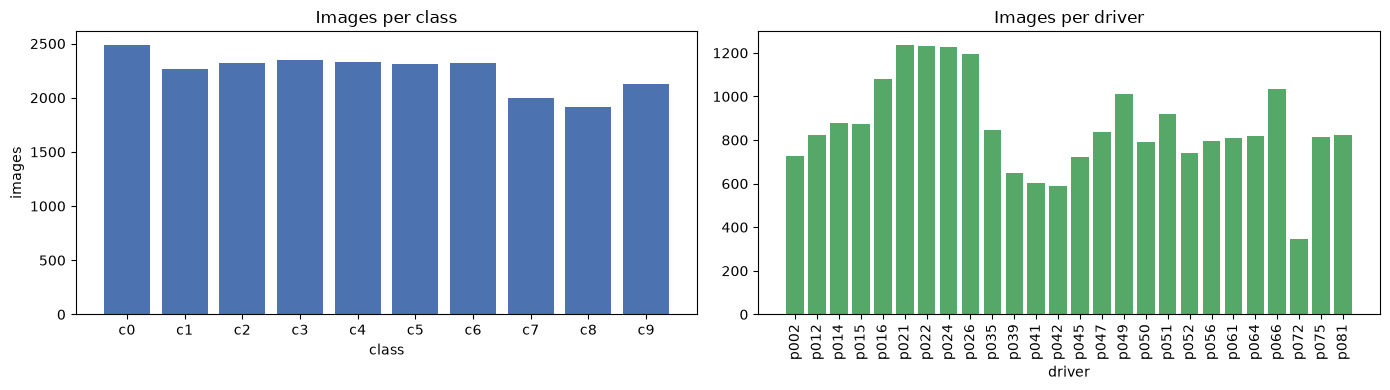

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
counts = df["classname"].value_counts().reindex(CLASS_ORDER)
axes[0].bar(counts.index, counts.values, color="#4C72B0")
axes[0].set_title("Images per class")
axes[0].set_xlabel("class")
axes[0].set_ylabel("images")

per_subject = df["subject"].value_counts().sort_index()
axes[1].bar(per_subject.index, per_subject.values, color="#55A868")
axes[1].set_title("Images per driver")
axes[1].set_xlabel("driver")
axes[1].tick_params(axis="x", rotation=90)
save_fig("fig01_class_and_driver_balance")

**Figure 1. Class and driver balance.** *Left.* The ten classes are close to balanced, so accuracy and macro-F1 will behave similarly and no re-weighting is needed. *Right.* Images per driver vary, and there are only 26 drivers in total, which is why we treat the driver as the unit of generalization (every fold holds out entire drivers) rather than the individual image.

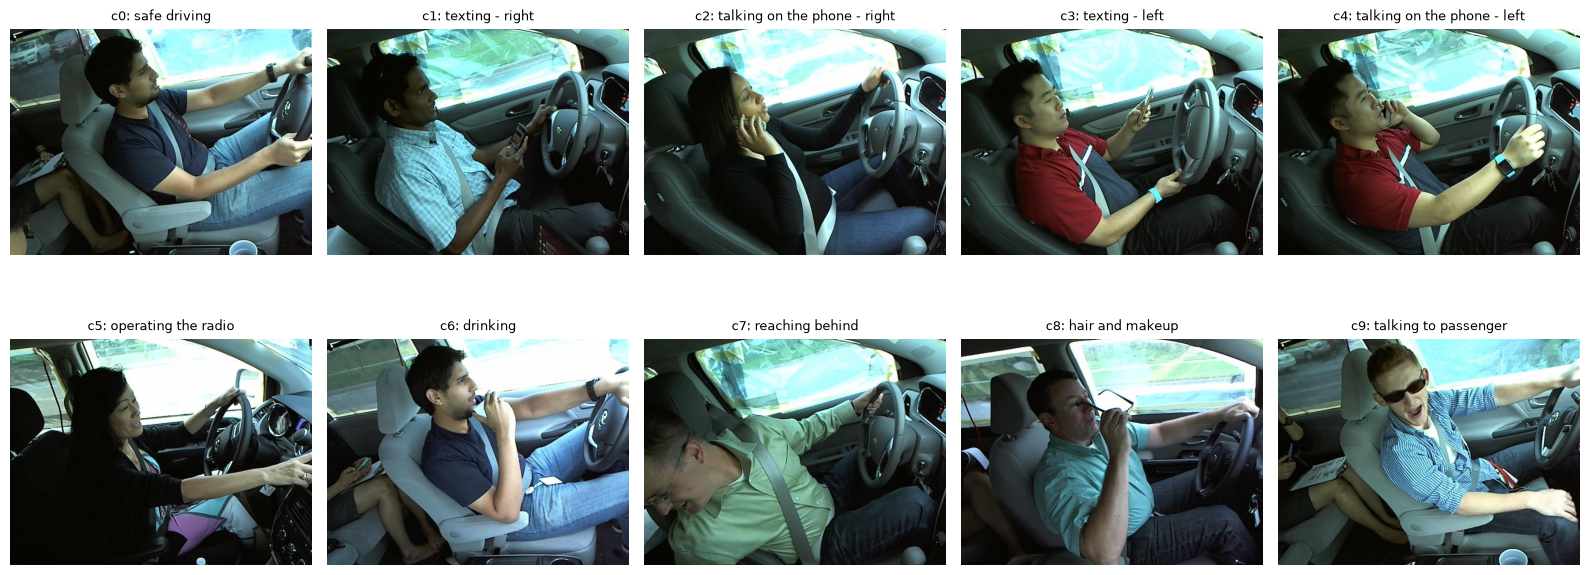

In [27]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
rng = np.random.default_rng(SEED)
for ax, cid in zip(axes.ravel(), CLASS_ORDER):
    row = df[df["classname"] == cid].iloc[rng.integers(0, (df["classname"] == cid).sum())]
    ax.imshow(Image.open(row["path"]).convert("RGB"))
    ax.axis("off")
    ax.set_title(f"{cid}: {CLASS_NAMES[cid]}", fontsize=9)
save_fig("fig02_class_examples")

**Figure 2. One example per class.** Note that `c1`/`c3` (texting) and `c2`/`c4` (phone call) differ only in *which hand* is used. This left/right distinction is exactly why a naive horizontal-flip augmentation corrupts the labels, and why we design a label-consistent flip.

## 2. Pose keypoint extraction and image caching

**Pose stream input.** We run a frozen, off-the-shelf Keypoint R-CNN (torchvision, COCO-pretrained) once over every image and keep nine upper-body keypoints (nose, both ears, both shoulders, both elbows, and both wrists). Coordinates are normalized to [0, 1] by image width/height. If no person is detected above `POSE_SCORE_THRESH`, the keypoints are zero and a `detected` flag is 0. Detection runs at the native 640 x 480 resolution. The results are cached because this is the slowest preprocessing step and does not change between experiments. The cache also stores the image filenames, so a cache that no longer matches the dataframe raises an error instead of being used.

In [15]:
# COCO keypoint ids -> 9 upper-body joints
COCO_IDX = [0, 3, 4, 5, 6, 7, 8, 9, 10]
KP_NAMES = [
    "nose",
    "l_ear",
    "r_ear",
    "l_shoulder",
    "r_shoulder",
    "l_elbow",
    "r_elbow",
    "l_wrist",
    "r_wrist",
]
# Left and right swap used when mirroring an image, for example (l_ear, r_ear)
FLIP_PERM = [0, 2, 1, 4, 3, 6, 5, 8, 7]

POSE_BATCH_SIZE = 8
# Windows cannot spawn DataLoader workers for classes defined in a notebook
POSE_NUM_WORKERS = 0 if os.name == "nt" else min(4, os.cpu_count() or 1)
# cache name encodes the dataset size, so a cache from a different subset is never reused
POSE_CACHE = CACHE_DIR / f"keypoints_n{len(df)}.npz"


class FullResImages(torch.utils.data.Dataset):
    """Reads each JPEG at its native resolution (the pose detector sees the full frame)."""

    def __init__(self, paths):
        """Stores the image paths.

        Args:
            paths: Iterable of image file paths in dataframe row order.
        """
        self.paths = list(paths)

    def __len__(self):
        """Returns the number of images.

        Returns:
            The length of the path list.
        """
        return len(self.paths)

    def __getitem__(self, i):
        """Reads one image at its native resolution.

        Args:
            i: Row position of the image.

        Returns:
            A uint8 tensor of shape [3, H, W].
        """
        return TF.pil_to_tensor(Image.open(self.paths[i]).convert("RGB"))


def frame_keypoints(frame, out):
    """Turns one Keypoint R-CNN output into normalized keypoints plus a detected flag.

    Detections are sorted by score, so the first one is the most confident person (the driver).
    If its score is below POSE_SCORE_THRESH, the keypoints are zeros and the flag is 0.

    Args:
        frame: The uint8 image tensor [3, H, W] that was fed to the detector.
        out: The detector's output dict for that frame.

    Returns:
        Tuple (kp, flag): float32 array [9, 2] with (x, y) in [0, 1], and 1.0 if a person was found.
    """
    if len(out["scores"]) == 0 or out["scores"][0] < POSE_SCORE_THRESH:
        return np.zeros((len(COCO_IDX), 2), dtype=np.float32), 0.0
    height, width = frame.shape[1:]
    xy = out["keypoints"][0][COCO_IDX, :2].cpu().numpy()
    return np.clip(xy / np.array([width, height], dtype=np.float32), 0, 1), 1.0


@torch.no_grad()
def extract_keypoints(paths):
    """Runs a frozen Keypoint R-CNN over every image once.

    Args:
        paths: Image file paths, in dataframe row order.

    Returns:
        Tuple (kps, det): float32 arrays [N, 9, 2] (x, y normalized to [0, 1])
        and [N] (1 = person found).
    """
    weights = models.detection.KeypointRCNN_ResNet50_FPN_Weights.DEFAULT
    detector = models.detection.keypointrcnn_resnet50_fpn(weights=weights).to(device).eval()
    loader = torch.utils.data.DataLoader(
        FullResImages(paths),
        batch_size=POSE_BATCH_SIZE,
        shuffle=False,  # row order must match the dataframe
        num_workers=POSE_NUM_WORKERS,
        collate_fn=list,  # frames may differ in size, so keep them as a list
    )

    results = []
    for frames in tqdm(loader, desc="Pose extraction"):
        outputs = detector([f.to(device).float() / 255 for f in frames])
        results += [frame_keypoints(f, o) for f, o in zip(frames, outputs, strict=True)]

    del detector
    torch.cuda.empty_cache()  # free GPU memory for training
    kps = np.stack([kp for kp, _ in results])
    det = np.array([flag for _, flag in results], dtype=np.float32)
    return kps, det


if POSE_CACHE.exists():
    cached = np.load(POSE_CACHE, allow_pickle=False)
    # the image order must be identical so this guards against a stale cache
    if not np.array_equal(cached["img"], df["img"].to_numpy(dtype=str)):
        raise ValueError(
            f"{POSE_CACHE} does not match the current dataframe; delete it to rebuild."
        )
    KPS = torch.from_numpy(cached["kps"])
    DET = torch.from_numpy(cached["det"])
    print(f"Loaded pose cache: {POSE_CACHE}")
else:
    kps, det = extract_keypoints(df["path"])
    np.savez(POSE_CACHE, kps=kps, det=det, img=df["img"].to_numpy(dtype=str))
    KPS, DET = torch.from_numpy(kps), torch.from_numpy(det)
    print(f"Saved pose cache: {POSE_CACHE}")

assert len(KPS) == len(DET) == len(df)
print(f"Keypoints {tuple(KPS.shape)} | person detected in {DET.mean():.1%} of frames")


Pose extraction:   0%|          | 0/2803 [00:00<?, ?it/s]

Saved pose cache: cache\keypoints_n22424.npz
Keypoints (22424, 9, 2) | person detected in 100.0% of frames


In [16]:
df["pose_detected"] = DET.numpy()
det_by_class = (
    df.groupby("classname")["pose_detected"].mean().reindex(CLASS_ORDER).rename("detection_rate")
)
det_table = det_by_class.to_frame()
det_table["class_name"] = [CLASS_NAMES[c] for c in det_table.index]
display(det_table.style.format({"detection_rate": "{:.1%}"}))
det_table.to_csv(OUT_DIR / "table_pose_detection_rate.csv")

,detection_rate,class_name
classname,,
c0,100.0%,safe driving
c1,100.0%,texting - right
c2,100.0%,talking on the phone - right
c3,100.0%,texting - left
c4,100.0%,talking on the phone - left
c5,100.0%,operating the radio
c6,100.0%,drinking
c7,100.0%,reaching behind
c8,100.0%,hair and makeup


**Table 3. Pose detection rate.** Fraction of frames with an accepted pose detection per class. A low rate in a class (typically hands near the face or reaching backwards) would mean the pose stream has less to offer there, so the full model must fall back on visual features. Here the detector found the driver in every frame.

### 2.1 Image caching

**CNN input.** Every image is resized once to `IMG_SIZE` x `IMG_SIZE` (uint8, antialiased) and stored in a single `.npy` file, so training reads from memory instead of decoding 22k JPEGs every epoch. The cache name encodes the dataset size and resolution, so a cache built with different settings is never reused, and the file is only renamed into place once complete, so an interrupted run never leaves a partial cache. This is separate from pose extraction, which runs on the native 640 x 480 frames. Both caches share the dataframe row order.

In [17]:
IMG_CACHE_BATCH_SIZE = 64
# Windows cannot spawn DataLoader workers for classes defined in a notebook
IMG_NUM_WORKERS = 0 if os.name == "nt" else min(4, os.cpu_count() or 1)
# cache name encodes dataset size and resolution, so a stale cache is never reused
IMG_CACHE = CACHE_DIR / f"images_n{len(df)}_s{IMG_SIZE}.npy"


class ResizedImages(torch.utils.data.Dataset):
    """Reads each JPEG and resizes it to IMG_SIZE x IMG_SIZE."""

    def __init__(self, paths):
        """Stores the image paths.

        Args:
            paths: Iterable of image file paths in dataframe row order.
        """
        self.paths = list(paths)

    def __len__(self):
        """Returns the number of images.

        Returns:
            The length of the path list.
        """
        return len(self.paths)

    def __getitem__(self, i):
        """Reads and resizes one image.

        Args:
            i: Row position of the image.

        Returns:
            A uint8 tensor of shape [3, IMG_SIZE, IMG_SIZE].
        """
        image = TF.pil_to_tensor(Image.open(self.paths[i]).convert("RGB"))
        return TF.resize(image, [IMG_SIZE, IMG_SIZE], antialias=True)


def build_image_cache(paths, out_path):
    """Resizes every image once and writes them to a single uint8 .npy file.

    Writes straight to disk batch by batch (no second copy in RAM), and renames the
    file only when finished, so an interrupted run never leaves a half-written cache.

    Args:
        paths: Image file paths, in dataframe row order.
        out_path: Destination .npy path.
    """
    loader = torch.utils.data.DataLoader(
        ResizedImages(paths),
        batch_size=IMG_CACHE_BATCH_SIZE,
        shuffle=False,  # row order must match the dataframe
        num_workers=IMG_NUM_WORKERS,
    )
    tmp_path = out_path.with_suffix(".tmp.npy")
    images = np.lib.format.open_memmap(
        tmp_path, mode="w+", dtype=np.uint8, shape=(len(paths), 3, IMG_SIZE, IMG_SIZE)
    )
    start = 0
    for batch in tqdm(loader, desc="Resizing images"):
        images[start : start + len(batch)] = batch.numpy()
        start += len(batch)
    images.flush()
    del images
    tmp_path.replace(out_path)


if IMG_CACHE.exists():
    print(f"Loaded image cache: {IMG_CACHE}")
else:
    build_image_cache(df["path"], IMG_CACHE)
    print(f"Saved image cache: {IMG_CACHE}")

IMAGES = torch.from_numpy(np.load(IMG_CACHE))  # uint8 [N, 3, IMG_SIZE, IMG_SIZE]
assert len(IMAGES) == len(df)
print(f"Images {tuple(IMAGES.shape)} ({IMAGES.numel() / 1e9:.2f} GB, uint8)")


Resizing images:   0%|          | 0/351 [00:00<?, ?it/s]

Saved image cache: cache\images_n22424_s224.npy
Images (22424, 3, 224, 224) (3.38 GB, uint8)


### 2.2 Pose keypoint overlay


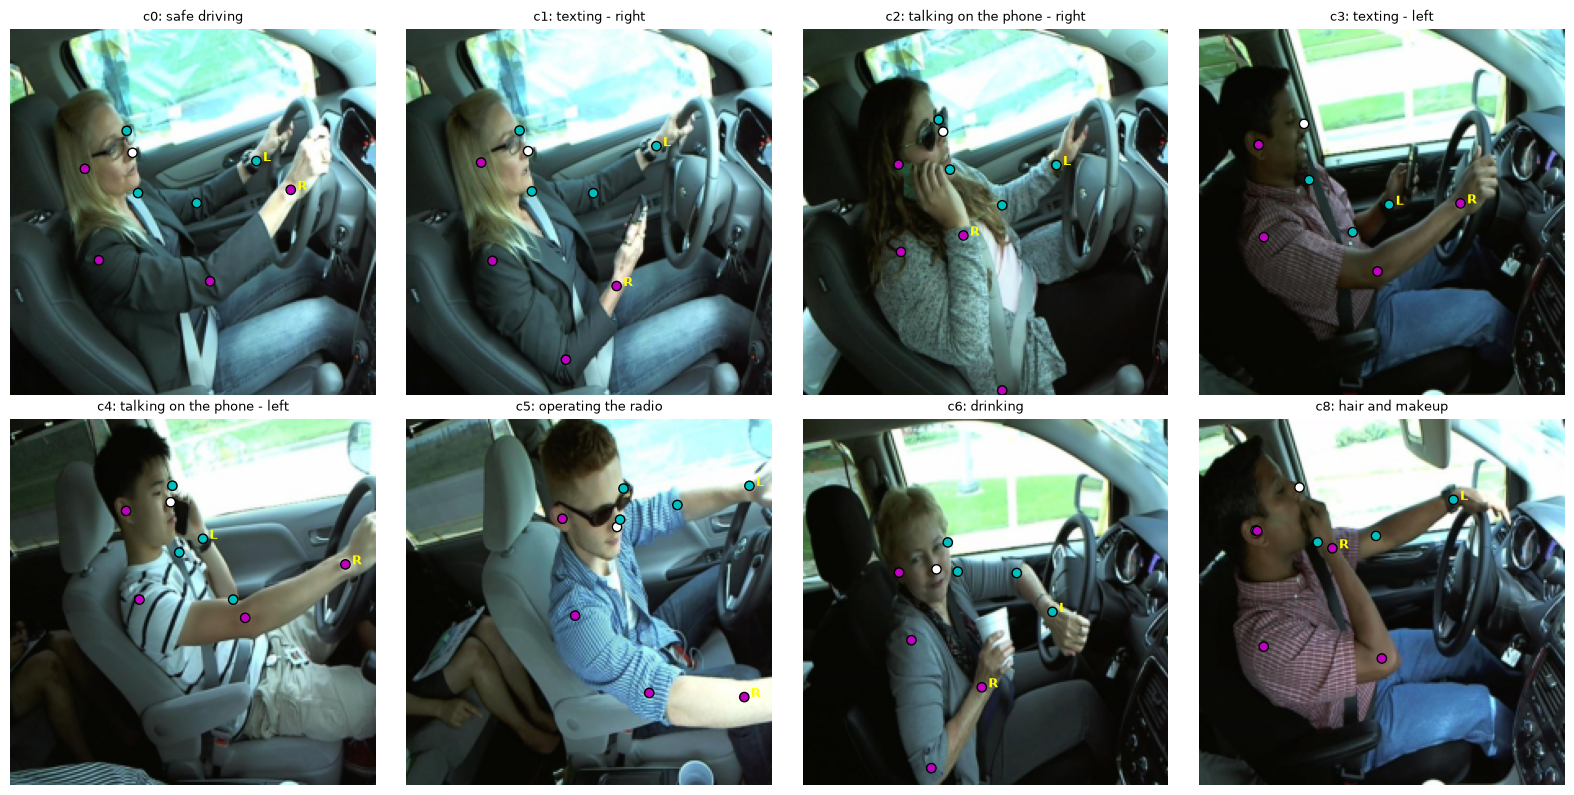

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
rng = np.random.default_rng(1)
for ax, cid in zip(axes.ravel(), ["c0", "c1", "c2", "c3", "c4", "c5", "c6", "c8"]):
    i = int(rng.choice(np.where(df["classname"] == cid)[0]))
    ax.imshow(IMAGES[i].permute(1, 2, 0).numpy())
    ax.axis("off")
    if DET[i] > 0:
        xy = KPS[i].numpy() * IMG_SIZE  # normalized [0, 1] -> pixels of the resized image
        ax.scatter(
            xy[:, 0], xy[:, 1], c=["w", "c", "m", "c", "m", "c", "m", "c", "m"], s=45, edgecolor="k"
        )
        for (x, y), name in zip(xy, KP_NAMES, strict=True):
            if name in ("l_wrist", "r_wrist"):
                ax.text(x + 4, y, name[0].upper(), color="yellow", fontsize=9, weight="bold")
    ax.set_title(f"{cid}: {CLASS_NAMES[cid]}", fontsize=9)
save_fig("fig03_pose_keypoints")

**Figure 3. Detected keypoints.** Keypoints overlaid on the cached `IMG_SIZE` x `IMG_SIZE` images (cyan = person's left side, magenta = right side, `L`/`R` mark wrists). A sanity check that the keypoints land on the anatomy we expect, and that the normalized coordinates line up with the resized images the CNN sees.

## 3. Label-consistent semantic flip

A plain horizontal flip is a standard augmentation, but is wrong for this task. A mirrored texting with the right hand image looks like texting with the left hand, yet, it would keep the label `c1`. Because of these, we flip the image and swap the label for examples like that.

* `c1 <-> c3` (texting right/left) and `c2 <-> c4` (phone right/left)
* Every other class (`c0`, `c5`-`c9`) keeps its label
* All ten classes are flipped with the same probability. If only some classes were mirrored, a mirrored cabin would itself reveal the class (a mirrored frame could never be `c5`-`c8`). That is a shortcut the network could learn. Uniform flipping makes the flip state independent of the label. The cost is that mirrored `c5`-`c8` frames are less natural (the radio ends up on the other side).

The keypoints are mirrored consistently, with `x -> 1 - x` and the left and right joints swapped. All augmentation is done on GPU tensors, per sample, with probability 0.5 per sample.

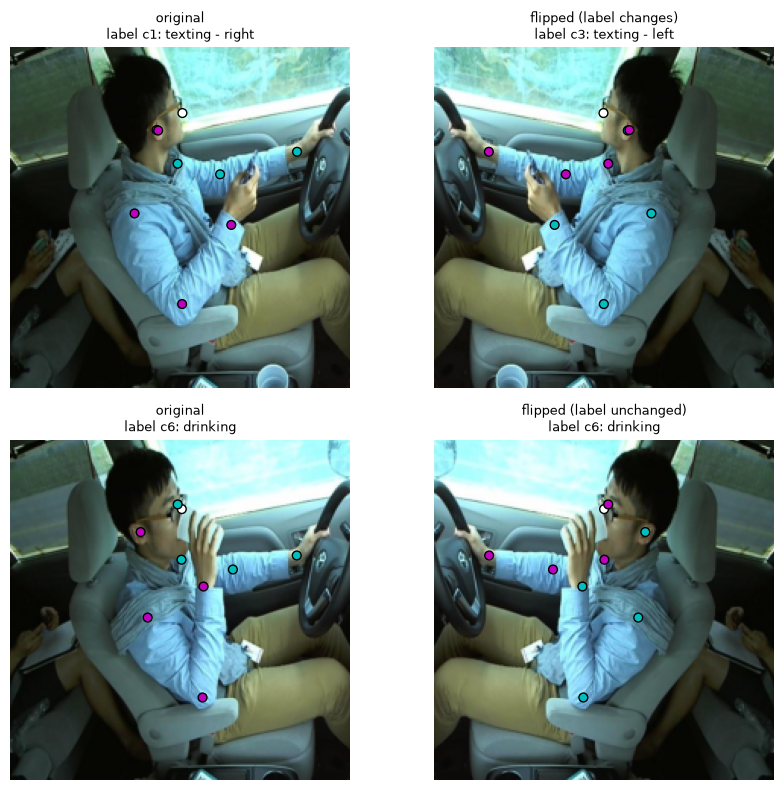

In [23]:
# the label a class-c image gets after mirroring (c1<->c3, c2<->c4, others unchanged)
SWAP_T = torch.tensor([0, 3, 4, 1, 2, 5, 6, 7, 8, 9], device=device)
FLIP_PERM_T = torch.tensor(FLIP_PERM, device=device)


def flip_batch(x, kp, y, p=0.5):
    """Horizontally flips samples, keeping image, keypoints and label consistent.

    Every sample, whatever its class, is flipped with probability `p`. Flipping swaps the label (c1<->c3, c2<->c4), mirrors the
    image, and mirrors the keypoints (x -> 1 - x, with left/right joints swapped).

    Args:
        x: Float image batch of shape [B, 3, H, W].
        kp: Keypoints of shape [B, 9, 2], normalized to [0, 1] as (x, y).
        y: Long class labels of shape [B].
        p: Probability of flipping each sample.

    Returns:
        Tuple (x, kp, y) of new tensors with the same shapes as the inputs.
    """
    do = (
        torch.rand(len(y), device=y.device) < p
    )  # independent per-sample coin toss, same p for every class
    x = torch.where(do[:, None, None, None], x.flip(-1), x)
    # Mirror the keypoint x values, then relabel left and right joints
    kp_f = kp[:, FLIP_PERM_T].clone()
    kp_f[..., 0] = 1 - kp_f[..., 0]
    kp = torch.where(do[:, None, None], kp_f, kp)
    y = torch.where(do, SWAP_T[y], y)
    return x, kp, y


# visual output of a real right-hand texting frame
EXAMPLES = [("c1", "label changes"), ("c6", "label unchanged")]
fig, axes = plt.subplots(len(EXAMPLES), 2, figsize=(9, 4 * len(EXAMPLES)))
for r, (cname, note) in enumerate(EXAMPLES):
    rows = np.where(df["classname"] == cname)[0]
    i = int(rows[100 % len(rows)])
    xi = (IMAGES[i : i + 1].float() / 255).to(device)
    ki = KPS[i : i + 1].to(device)
    yi = torch.tensor(df["y"].values[i : i + 1]).to(device)
    xf, kf, yf = flip_batch(xi, ki, yi, p=1.0)  # p=1 forces the flip
    for ax, (xx, kk, yy, t) in zip(
        axes[r], [(xi, ki, yi, "original"), (xf, kf, yf, f"flipped ({note})")]
    ):
        ax.imshow(xx[0].permute(1, 2, 0).cpu().numpy())
        ax.axis("off")
        p_ = kk[0].cpu().numpy() * IMG_SIZE
        ax.scatter(
            p_[:, 0], p_[:, 1], c=["w", "c", "m", "c", "m", "c", "m", "c", "m"], s=40, edgecolor="k"
        )
        ax.set_title(f"{t}\nlabel c{int(yy)}: {CLASS_NAMES[f'c{int(yy)}']}", fontsize=9)
save_fig("fig04_label_consistent_flip")

**Figure 4. The label-consistent flip.** The top row shows a `c1` (texting, right hand) frame and its mirror image, now labeled `c3` (texting, left hand), so the label changes. The bottom row shows a `c6` (drinking) frame and its mirror image, which keeps the label `c6` because the class has no left/right counterpart, so the label is unchanged. In both rows the keypoints are mirrored and left/right joints swapped (cyan = left, magenta = right). Every class is flipped with the same probability. Only the handed classes change label.

*Limitation (for the discussion).* The camera sits on one side of the cabin, so a mirrored frame also mirrors the viewpoint. This is why the flip is an ablation row (B) and not assumed to help.

## 4. Model, an identity-disentangled and pose-guided network

* **Visual stream.** A ResNet-18 CNN, trained twice, from random initialization and from ImageNet weights (the ladder is run for both). Global-pooled features `f_vis` capture objects (phone, cup, radio) and appearance.
* **Pose stream.** The 9 keypoints (18 centered coordinates) plus a detected flag, 19 numbers in all, go through a small 2-layer MLP to `f_pose` (64-d). The MLP is left to learn arm angles and hand-to-face distances itself.
* **Gradient Reversal Layer (GRL).** The identity in the forward pass, but multiplies gradients by `-lambda` in the backward pass. A driver head tries to predict which *training* driver is in the image from `f_vis`. Because of the GRL, the backbone is pushed to make that prediction *impossible*, i.e. to discard driver-identifying cues while the class head still needs the action cues. `lambda` ramps up from 0 with the standard DANN schedule `2/(1+exp(-10p)) - 1`, with `p` the training progress.
* Only the visual features go through the adversary. The pose stream is only 19 numbers with no background or clothing, so we do not apply the adversary to it (we do not test whether body proportions still reveal the driver).

The same class `DriverNet` builds all five ablation models. The architecture is chosen by the configuration list in Section 6.

In [ ]:
class GradReverse(torch.autograd.Function):
    """Gradient Reversal Layer that is the identity forward and scales gradients by -lam backward."""

    @staticmethod
    def forward(ctx, x, lam):
        """Passes the input through unchanged.

        Args:
            ctx: Autograd context that stores `lam` for the backward pass.
            x: Input features.
            lam: Reversal strength, a non-negative float.

        Returns:
            A view of `x` (the identity).
        """
        ctx.lam = lam
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad):
        """Reverses and scales the incoming gradient.

        Args:
            ctx: Autograd context holding `lam`.
            grad: Gradient flowing back from the driver head.

        Returns:
            Tuple of the gradient for `x` (multiplied by -lam) and None for `lam`.
        """
        return -ctx.lam * grad, None


# 9 keypoints x (x, y) = 18 numbers, plus 1 "person detected" flag
POSE_DIM = 19


def pose_features(kp, det):
    """Body-centered, shoulder-width-normalized keypoints for the pose MLP.

    The origin is the mid-shoulder (joint ids 3 and 4) and the unit is the shoulder width, so where the
    driver sits in the frame and how large they are do not reach the network (they would be identity cues).

    Args:
        kp: Keypoints [B, 9, 2] in [0, 1] image coordinates.
        det: Detection flag [B] (1 = person found).

    Returns:
        Tensor of shape [B, POSE_DIM] with 18 body-centered coordinates (zeroed if nothing was
        detected) and the detection flag.
    """
    mid = 0.5 * (kp[:, 3:4] + kp[:, 4:5])  # [B, 1, 2]
    width = (kp[:, 3] - kp[:, 4]).norm(dim=-1).clamp(min=MIN_SHOULDER_WIDTH)  # [B]
    coords = ((kp - mid) / width[:, None, None]).flatten(1)  # [B, 18]
    return torch.cat([coords * det[:, None], det[:, None]], dim=1)


class DriverNet(nn.Module):
    """ResNet-18 classifier with an optional pose stream and gradient-reversal driver head.

    Attributes:
        use_pose: Whether pose-keypoint features are fused into the class head.
        use_grl: Whether the driver adversary head is used.
    """

    def __init__(self, use_pose, use_grl, n_drivers, init="scratch"):
        """Builds the network.

        Args:
            use_pose: Fuse pose-keypoint features into the class head.
            use_grl: Add the gradient-reversal driver head.
            n_drivers: Number of training drivers, the output size of the driver head.
            init: "scratch" for random weights or "imagenet" for pretrained weights.
        """
        super().__init__()
        self.use_pose = use_pose
        self.use_grl = use_grl
        # Input normalization lives inside the model because it depends on the initialization
        # [-1, 1] for random init, the ImageNet statistics for the pretrained weights.
        mean, std = (
            ([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
            if init == "imagenet"
            else ([0.5] * 3, [0.5] * 3)
        )
        self.register_buffer("mean", torch.tensor(mean).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(std).view(1, 3, 1, 1))

        # ResNet-18 trunk, random init (init="scratch") or ImageNet weights (init="imagenet")
        resnet = models.resnet18(
            weights=models.ResNet18_Weights.IMAGENET1K_V1 if init == "imagenet" else None
        )
        self.features = nn.Sequential(
            resnet.conv1,
            resnet.bn1,
            resnet.relu,
            resnet.maxpool,
            resnet.layer1,
            resnet.layer2,
            resnet.layer3,
            resnet.layer4,
        )
        # Input of shape [B, 3, 224, 224] becomes [B, 512, 7, 7]

        self.pool = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
        )
        # [B, 512, 7, 7] -> [B, 512]   (this is f_vis)

        # Pose stream, a small MLP over the keypoints
        if use_pose:
            self.pose_mlp = nn.Sequential(
                nn.Linear(POSE_DIM, 64),
                nn.ReLU(),
                nn.Linear(64, 64),
                nn.ReLU(),
            )
            # [B, 19] -> [B, 64]   (this is f_pose)

        # Class head sees f_vis, plus f_pose if pose fusion is on
        fused_dim = 512 + (64 if use_pose else 0)
        self.classifier = nn.Sequential(
            nn.Dropout(p=0.30),
            nn.Linear(fused_dim, NUM_CLASSES),
        )

        # Driver head (training only) guesses which driver is shown from f_vis
        if use_grl:
            self.driver_head = nn.Sequential(
                nn.Linear(512, 256),
                nn.ReLU(),
                nn.Linear(256, n_drivers),
            )

    def encode(self, x):
        """Extracts visual features.

        Args:
            x: Image batch of shape [B, 3, H, W] with values in [0, 1].

        Returns:
            Tuple of the last feature map [B, 512, 7, 7] and the pooled features f_vis [B, 512].
        """
        fmap = self.features(
            (x - self.mean) / self.std
        )  # x is in [0, 1] and fmap has shape [B, 512, 7, 7] (also used by Grad-CAM)
        return fmap, self.pool(fmap)  # and f_vis has shape [B, 512]

    def classify(self, f_vis, pose_f):
        """Predicts the distraction class.

        Args:
            f_vis: Pooled visual features [B, 512].
            pose_f: Pose features [B, POSE_DIM], ignored when pose fusion is off.

        Returns:
            Class logits [B, 10].
        """
        if self.use_pose:
            f_vis = torch.cat([f_vis, self.pose_mlp(pose_f)], dim=1)  # [B, 576]
        return self.classifier(f_vis)  # [B, 10]

    def forward(self, x, pose_f, lam=0.0):
        """Runs the full network.

        Args:
            x: Image batch [B, 3, H, W] with values in [0, 1].
            pose_f: Pose features [B, POSE_DIM].
            lam: Gradient-reversal strength for the driver head.

        Returns:
            Tuple of class logits [B, 10], driver logits (None without the GRL) and f_vis [B, 512].
        """
        _, f_vis = self.encode(x)
        logits = self.classify(f_vis, pose_f)

        # The GRL flips the gradient. The driver head learns to name the driver,
        # while the backbone is pushed to make that impossible.
        driver_logits = None
        if self.use_grl:
            driver_logits = self.driver_head(GradReverse.apply(f_vis, lam))
        return logits, driver_logits, f_vis


# quick numeric check of the pose features and parameter counts
_f = pose_features(torch.rand(4, 9, 2), torch.tensor([1.0, 1.0, 0.0, 1.0]))
assert _f.shape == (4, POSE_DIM) and torch.all(_f[2, :-1] == 0), "undetected rows must be all-zero"
rows = []
for name, up, ug in [
    ("A baseline", False, False),
    ("B +flip (same net as A)", False, False),
    ("C +GRL", False, True),
    ("D +GRL +pose", True, True),
]:
    m = DriverNet(up, ug, n_drivers=18)
    rows.append({"model": name, "parameters (M)": sum(p.numel() for p in m.parameters()) / 1e6})
param_table = pd.DataFrame(rows)
display(param_table.style.format({"parameters (M)": "{:.2f}"}))
param_table.to_csv(OUT_DIR / "table_model_parameters.csv", index=False)

**Table. Model size.** The pose MLP and driver head add only a small fraction of parameters to the ResNet-18 backbone, so any improvement cannot be explained by simply having a bigger network. (The driver head is shown here for 18 training drivers, its output size follows the actual number of training drivers in each fold. The GRL head is training-only and is not used at inference.)

## 5. Training, evaluation and analysis utilities

* `get_batch` assembles a GPU batch, applies color jitter (all configurations) and the label-consistent flip (only configurations that request it).
* `run_experiment` trains one model with AdamW + OneCycle schedule and mixed precision. Every epoch it evaluates on the held-out drivers and records loss/accuracy/F1.
* **Driver-identity probe.** After training we freeze the network, extract `f_vis` for the held-out drivers, split their frames 50/50 at random, and fit a linear classifier to predict *which driver* a frame comes from. Higher probe accuracy means identity is more linearly recoverable from the features. A successful adversary should lower it. (Frames of one driver are highly similar, so absolute values are high, compare *between* configurations, against chance = 1 / number of held-out drivers.)
* **Grad-CAM.** Class-discriminative heat-maps from the last convolutional feature map, to see *where* each model looks.

### 5.1 Batches, metrics, and prediction

In [ ]:
def get_batch(idx, train, use_flip=False):
    """Builds one GPU batch from the cached tensors, with optional augmentation.

    Args:
        idx: NumPy int array of dataframe row indices for this batch.
        train: If True, apply augmentation (color jitter and, if requested, the flip).
        use_flip: If True (and train is True), apply the label-consistent flip.

    Returns:
        Tuple (x, pose_f, y): images in [0, 1] [B,3,H,W] (the model normalizes them), pose features [B,POSE_DIM]
        and class labels [B] (already swapped if a sample was flipped).
    """
    ti = torch.from_numpy(idx)
    x = IMAGES[ti].to(device, non_blocking=True).float() / 255  # uint8 -> float in [0, 1]
    kp, det, y = KPS[ti].to(device), DET[ti].to(device), LABELS[ti].to(device)
    if train:
        # Flip first so keypoints and labels are transformed together with the pixels.
        if use_flip:
            x, kp, y = flip_batch(x, kp, y)
        # Mild per-image contrast and brightness jitter (simulates lighting changes).
        m = x.mean(dim=(1, 2, 3), keepdim=True)
        c = torch.empty(len(x), 1, 1, 1, device=device).uniform_(0.85, 1.15)
        b = torch.empty(len(x), 1, 1, 1, device=device).uniform_(0.85, 1.15)
        x = ((x - m) * c + m) * b
        x = x.clamp(0, 1)
    return x, pose_features(kp, det), y


def compute_metrics(y_true, y_pred, probs):
    """Computes the evaluation metrics reported throughout the notebook.

    Args:
        y_true: Integer ground-truth labels [N].
        y_pred: Integer predicted labels [N].
        probs: Predicted class probabilities [N, NUM_CLASSES].

    Returns:
        Dict with accuracy, macro precision/recall/F1, macro one-vs-rest ROC-AUC and
        multi-class log-loss (the Kaggle competition metric, lower is better).
    """
    try:
        auc = roc_auc_score(
            y_true,
            probs / probs.sum(1, keepdims=True),
            multi_class="ovr",
            average="macro",
            labels=list(range(NUM_CLASSES)),
        )
    except ValueError:  # a class missing from y_true
        auc = float("nan")
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "roc_auc": auc,
        "log_loss": log_loss(y_true, np.clip(probs, 1e-7, 1), labels=list(range(NUM_CLASSES))),
    }


@torch.no_grad()
def predict(model, idx):
    """Runs inference on the given rows without augmentation.

    Args:
        model: A trained DriverNet.
        idx: NumPy int array of dataframe row indices.

    Returns:
        Tuple (probs, feats): softmax probabilities [N, NUM_CLASSES] and the pooled
        visual features f_vis [N, 512] (used by the driver-identity probe).
    """
    model.eval()
    probs, feats = [], []
    for s in range(0, len(idx), 256):  # Large batches are fine because no gradients are stored
        x, pf, _ = get_batch(idx[s : s + 256], train=False)
        with torch.autocast(device.type, enabled=USE_AMP):
            logits, _, f = model(x, pf)
        probs.append(F.softmax(logits.float(), 1).cpu())
        feats.append(f.float().cpu())
    return torch.cat(probs).numpy(), torch.cat(feats).numpy()

### 5.2 Driver-identity probe

A linear classifier that tries to name the driver from the frozen visual features.

In [ ]:
def _probe_fit_score(Xa, sa, Xb, sb):
    """Fits a standardized logistic-regression driver classifier and scores it.

    Args:
        Xa: Training features [Na, D].
        sa: Driver ids for the training features.
        Xb: Test features [Nb, D].
        sb: Driver ids for the test features.

    Returns:
        Accuracy of the classifier on (Xb, sb).
    """
    sc = StandardScaler().fit(Xa)
    clf = LogisticRegression(max_iter=200, C=0.1).fit(sc.transform(Xa), sa)
    return clf.score(sc.transform(Xb), sb)


def driver_probe(feats, subjects, labels, seed=0, max_n=6000, mode="class_split"):
    """Measures how well driver identity can be read out of the visual features.

    A linear classifier is trained to name the driver. Frames come from the held-out
    drivers, so a high score means the features encode *general* identity cues, not just
    those of the training drivers.

    There are two split modes.
      * ``"class_split"`` (primary) trains on frames of classes c0-c4 and tests on frames of
        classes c5-c9, then does the reverse and averages. State Farm frames come from video bursts,
        so a random split lets a probe match frame t with the near-identical frame t+1 of the
        same action. Separating by action class removes that shortcut.
      * ``"random"`` (secondary) is a stratified random 50/50 split. It is inflated by the near-duplicate
        frames, so report it only next to the class split.

    Args:
        feats: Visual features [N, D] of the held-out frames.
        subjects: Driver id per frame, length N.
        labels: Integer class label per frame, length N.
        seed: Seed for the subsample and the split.
        max_n: Maximum number of frames used (keeps the probe fast).
        mode: "class_split" or "random".

    Returns:
        Accuracy in [0, 1] of predicting the driver on the unseen half.
    """
    rng = np.random.default_rng(seed)
    sel = rng.permutation(len(feats))[:max_n]
    X, s, y = feats[sel], subjects[sel], labels[sel]
    if mode == "random":
        Xa, Xb, sa, sb = train_test_split(X, s, test_size=0.5, stratify=s, random_state=seed)
        return _probe_fit_score(Xa, sa, Xb, sb)
    low = y < 5  # classes c0-c4 vs c5-c9
    scores = []
    for train_mask in (low, ~low):
        test_mask = ~train_mask
        common = np.isin(
            s, sorted(set(s[train_mask]) & set(s[test_mask]))
        )  # drivers present in both halves
        tr, te = train_mask & common, test_mask & common
        scores.append(_probe_fit_score(X[tr], s[tr], X[te], s[te]))
    return float(np.mean(scores))

### 5.3 Training and evaluating one configuration

In [ ]:
def build_training(cfg, tr_idx):
    """Builds the model, optimizer, LR schedule, and loss scaler for one run.

    Args:
        cfg: Configuration dict with the keys "pose", "grl" and "init" (see CONFIGS).
        tr_idx: NumPy array of training row indices.

    Returns:
        Tuple of the model, optimizer, scheduler, gradient scaler, driver labels (one per dataframe
        row, -1 for rows outside the training set) and the number of steps per epoch.
    """
    # Map each training driver to a class index 0..K-1 for the adversary's target
    train_subjects = sorted(set(SUBJECTS[tr_idx]))
    sub2idx = {s: i for i, s in enumerate(train_subjects)}
    driver_lbl = torch.full((len(df),), -1, dtype=torch.long)  # -1 = not a training row
    for i in tr_idx:
        driver_lbl[i] = sub2idx[SUBJECTS[i]]

    # Two parameter groups, one for the trunk and one for the new heads (always newly initialized)
    model = DriverNet(cfg["pose"], cfg["grl"], len(train_subjects), cfg["init"]).to(device)
    head_params = [p for n, p in model.named_parameters() if not n.startswith("features.")]
    opt = torch.optim.AdamW(
        [
            {"params": model.features.parameters(), "lr": LR_BACKBONE[cfg["init"]]},
            {"params": head_params, "lr": LR_HEAD},
        ],
        weight_decay=WEIGHT_DECAY,
    )
    steps_per_epoch = len(tr_idx) // BATCH_SIZE
    sched = torch.optim.lr_scheduler.OneCycleLR(
        opt,
        max_lr=[LR_BACKBONE[cfg["init"]], LR_HEAD],
        total_steps=EPOCHS * steps_per_epoch,
        pct_start=0.2,
    )
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)  # loss scaling for fp16 stability
    return model, opt, sched, scaler, driver_lbl, steps_per_epoch


def train_one_epoch(model, cfg, opt, sched, scaler, perm, driver_lbl, step, total_steps):
    """Runs one training epoch.

    Args:
        model: The DriverNet being trained.
        cfg: Configuration dict with the keys "flip" and "grl".
        opt: Optimizer.
        sched: Per-step LR scheduler.
        scaler: Gradient scaler for mixed precision.
        perm: Shuffled training row indices for this epoch.
        driver_lbl: Driver class index per dataframe row, used as the adversary's target.
        step: Number of optimizer steps taken before this epoch.
        total_steps: Total number of steps in the run, used for the DANN ramp.

    Returns:
        Tuple of a stats dict and the updated step count. The stats hold the summed class loss
        ("loss"), the summed driver loss ("driver_loss"), the number of correct and seen frames
        ("correct" and "seen"), the last reversal strength ("lam") and the epoch time ("time_sec").
    """
    model.train()
    run_loss = run_drv = 0.0
    run_correct = n_seen = 0
    t_epoch = time.time()
    for b in range(len(perm) // BATCH_SIZE):
        idx = perm[b * BATCH_SIZE : (b + 1) * BATCH_SIZE]
        x, pf, y = get_batch(idx, train=True, use_flip=cfg["flip"])
        # Gradient-reversal strength grows from 0 so early training can learn the task first
        p = step / total_steps
        lam = LAMBDA_MAX * (2 / (1 + math.exp(-10 * p)) - 1) if cfg["grl"] else 0.0
        with torch.autocast(device.type, enabled=USE_AMP):
            logits, drv, _ = model(x, pf, lam)
            loss = F.cross_entropy(logits.float(), y)
            if cfg["grl"]:
                # The driver head minimizes this loss and the GRL makes the backbone maximize it
                d_loss = F.cross_entropy(drv.float(), driver_lbl[torch.from_numpy(idx)].to(device))
                loss_total = loss + d_loss
                run_drv += d_loss.item()
            else:
                loss_total = loss
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss_total).backward()
        scaler.step(opt)
        scaler.update()
        sched.step()
        run_loss += loss.item()
        run_correct += (logits.argmax(1) == y).sum().item()
        n_seen += len(y)
        step += 1
    stats = {
        "loss": run_loss,
        "driver_loss": run_drv,
        "correct": run_correct,
        "seen": n_seen,
        "lam": lam,
        "time_sec": time.time() - t_epoch,
    }
    return stats, step


def validate(model, va_idx):
    """Scores the held-out frames and returns the validation fields of a history record.

    Args:
        model: The DriverNet to evaluate.
        va_idx: NumPy array of validation row indices.

    Returns:
        Dict with "val_loss", "val_acc", "val_f1", "val_precision" and "val_recall".
    """
    probs, _ = predict(model, va_idx)
    y_va = LABELS[va_idx].numpy()
    m = compute_metrics(y_va, probs.argmax(1), probs)
    return {
        "val_loss": m["log_loss"],
        "val_acc": m["accuracy"],
        "val_f1": m["macro_f1"],
        "val_precision": m["macro_precision"],
        "val_recall": m["macro_recall"],
    }


def track_epoch(model, track):
    """Measures the identity and class signal on a fixed subset of held-out frames.

    Args:
        model: The DriverNet to evaluate.
        track: The tracking dict described in `run_experiment`.

    Returns:
        Tuple of a dict with "class_acc", "probe_acc" and "probe_acc_rand", and the features of the
        frames kept for t-SNE.
    """
    probs, feats = predict(model, track["probe_idx"])
    scores = {
        "class_acc": float((probs.argmax(1) == track["probe_y"]).mean()),
        "probe_acc": driver_probe(feats, track["probe_subj"], track["probe_y"]),
        "probe_acc_rand": driver_probe(feats, track["probe_subj"], track["probe_y"], mode="random"),
    }
    return scores, feats[track["vis_pos"]].copy()


def run_experiment(cfg, tr_idx, va_idx, tag, seed=SEED, verbose=True, monitor=True, track=None):
    """Trains one configuration on one fold and evaluates it on unseen drivers.

    Training uses AdamW with a OneCycle LR schedule and mixed precision. If the
    configuration enables the driver adversary, the loss is
    ``CE(class) + CE(driver)`` with the gradient reversal strength ramped up by the
    DANN schedule ``lam = LAMBDA_MAX * (2 / (1 + exp(-10 p)) - 1)``, p = progress in [0, 1].

    Args:
        cfg: Dict with boolean keys "flip", "grl", "pose" (see CONFIGS).
        tr_idx: NumPy array of training row indices.
        va_idx: NumPy array of validation row indices (disjoint drivers from tr_idx).
        tag: Short label used in progress printouts.
        seed: Random seed, identical across configurations for a paired comparison.
        verbose: If True, print one line per epoch.
        monitor: If True, score `va_idx` after every epoch (validation curves). Pass False
            when `va_idx` is the frozen test set. The test frames are then scored once, after
            the last epoch, and are never used to monitor or select anything.
        track: Optional dict that records the driver-identity signal while training (used for the
            Section 9 figure). Its keys are "probe_idx" (held-out rows to score), "probe_subj" and
            "probe_y" (their drivers and classes), "vis_pos" (positions inside probe_idx whose
            features are kept for t-SNE) and "snapshot_epochs" (1-based epochs at which to keep
            them). After every epoch the history gets "class_acc", "probe_acc" and
            "probe_acc_rand" on those frames. None (default) adds no cost.

    Returns:
        Dict with the keys "metrics" (final-epoch metrics), "history" (per-epoch records),
        "probs"/"pred"/"y"/"va_idx" (validation predictions), "probe_acc" (class-split),
        "probe_acc_rand" (random split) and "probe_chance" (driver-identity probe), "model", "train_time" and "snaps"
        (feature snapshots as a dict from epoch to array, empty unless `track` is given).
    """
    seed_everything(seed)
    model, opt, sched, scaler, driver_lbl, steps_per_epoch = build_training(cfg, tr_idx)
    total_steps = EPOCHS * steps_per_epoch

    history, snaps, step, t0 = [], {}, 0, time.time()
    for epoch in range(EPOCHS):
        perm = np.random.RandomState(seed + epoch).permutation(tr_idx)  # reshuffle each epoch
        stats, step = train_one_epoch(
            model, cfg, opt, sched, scaler, perm, driver_lbl, step, total_steps
        )
        rec = {
            "epoch": epoch + 1,
            "train_loss": stats["loss"] / steps_per_epoch,
            "train_acc": stats["correct"] / stats["seen"],
            "time_sec": stats["time_sec"],
            "driver_loss": stats["driver_loss"] / steps_per_epoch if cfg["grl"] else np.nan,
            "lambda": stats["lam"],
        }
        # End-of-epoch validation on held-out drivers (skipped with monitor=False for frozen test drivers)
        if monitor:
            rec.update(validate(model, va_idx))
        if track is not None:
            scores, snapshot = track_epoch(model, track)
            rec.update(scores)
            if epoch + 1 in track["snapshot_epochs"]:
                snaps[epoch + 1] = snapshot
        history.append(rec)
        if verbose:
            msg = (
                f"val loss {rec['val_loss']:.3f} acc {rec['val_acc']:.3f} f1 {rec['val_f1']:.3f}"
                if monitor
                else "(held-out frames not scored during training)"
            )
            print(
                f"  [{tag}] ep {epoch + 1}/{EPOCHS} train {rec['train_loss']:.3f} acc {rec['train_acc']:.3f} | {msg} | {time.time() - t0:.0f}s"
            )

    # Final evaluation with the trained model, plus the identity probe on the same frames.
    probs, feats = predict(model, va_idx)
    y_va = LABELS[va_idx].numpy()
    pred = probs.argmax(1)
    out = {
        "metrics": compute_metrics(y_va, pred, probs),
        "history": history,
        "probs": probs,
        "pred": pred,
        "y": y_va,
        "va_idx": va_idx,
        "probe_acc": driver_probe(feats, SUBJECTS[va_idx], y_va),  # class-held-out split (primary)
        "probe_acc_rand": driver_probe(
            feats, SUBJECTS[va_idx], y_va, mode="random"
        ),  # random split (inflated by near-duplicates)
        "probe_chance": 1 / len(set(SUBJECTS[va_idx])),
        "model": model,
        "snaps": snaps,
        "train_time": time.time() - t0,
    }
    return out

### 5.4 Grad-CAM

Class-discriminative heat-maps from the last convolutional feature map. 

In [ ]:
def grad_cam(model, x, pf, target):
    """Computes a Grad-CAM heat-map (Selvaraju et al., 2017) for one image.

    Weights each channel of the last conv feature map by the mean gradient of the
    target-class logit, sums over channels, and keeps only positive evidence.

    Args:
        model: A trained DriverNet.
        x: Normalized image of shape [1, 3, H, W].
        pf: Pose features of shape [1, POSE_DIM].
        target: Integer class whose evidence is visualized.

    Returns:
        NumPy array [IMG_SIZE, IMG_SIZE] scaled to [0, 1].
    """
    model.eval()
    with torch.enable_grad():  # gradients are needed here even though the model is in eval mode
        fmap, _ = model.encode(x)
        fmap.retain_grad()  # keep d(logit)/d(fmap) for the non-leaf feature map
        logits = model.classify(model.pool(fmap).flatten(1), pf)
        model.zero_grad()
        logits[0, target].backward()
        w = fmap.grad.mean(dim=(2, 3), keepdim=True)  # per-channel importance weights
        cam = F.relu((w * fmap).sum(1, keepdim=True))  # weighted sum, positive part only
    # upsample the coarse map to image size and normalize for display
    cam = (
        F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[0, 0]
        .detach()
        .cpu()
        .numpy()
    )
    return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

Utilities defined.


### 5.5 Split and sampling helpers

Diver-grouped split with a class-coverage check and a per-class sampling cap.

In [ ]:
Y_ALL = df["y"].to_numpy()


def select_group_split(rows, test_frac, n_seeds=200):
    """Driver-grouped train/test split of `rows`, searched over seeds so that every class is in both halves.

    Tries `n_seeds` GroupShuffleSplit seeds and keeps the split whose test share of *images* is closest to
    `test_frac`, among those where all ten classes appear in both halves (the selection rule).

    Args:
        rows: NumPy int array of dataframe row indices to split (e.g. DEV_IDX, so the frozen test drivers stay out).
        test_frac: Target fraction of images in the test half.
        n_seeds: Number of seeds to try.

    Returns:
        Tuple (train_rows, test_rows, seed): row indices into df (disjoint drivers) and the chosen seed.
    """
    rows = np.asarray(rows)
    sub = df.iloc[rows]
    best = None
    for seed in range(n_seeds):
        splitter = GroupShuffleSplit(n_splits=1, test_size=test_frac, random_state=seed)
        tr, te = next(splitter.split(sub, groups=sub["subject"]))
        gap = abs(len(te) / len(sub) - test_frac)
        complete = (
            sub["y"].iloc[tr].nunique() == NUM_CLASSES
            and sub["y"].iloc[te].nunique() == NUM_CLASSES
        )
        if complete and (best is None or gap < best[0]):
            best = (gap, seed, tr, te)
    if best is None:
        raise ValueError("no seed gave a split with all classes in both halves")
    _, seed, tr, te = best
    assert set(SUBJECTS[rows[tr]]).isdisjoint(SUBJECTS[rows[te]]), (
        "driver leakage between the two halves!"
    )
    return rows[tr], rows[te], seed

### 5.6 Analysis and plotting helpers

Small functions used by the results sections. They take their inputs as arguments where practical. The remaining notebook-level names they read (such as `CONFIGS`, `SHORT` and the image arrays) are all defined before they are called.

In [ ]:
# Small helpers shared by the analysis sections below
def tsne_2d(feats, seed=SEED):
    """Embeds features in 2D with PCA followed by t-SNE.

    Args:
        feats: Feature array [N, D].
        seed: Random seed for PCA and t-SNE.

    Returns:
        Array [N, 2] of embedded points.
    """
    z = StandardScaler().fit_transform(feats)
    z = PCA(n_components=min(50, z.shape[1], len(z) - 1), random_state=seed).fit_transform(z)
    return TSNE(
        n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=seed
    ).fit_transform(z)


def pm(s, digits=3):
    """Formats a Series as 'mean ± std' for the summary table.

    Args:
        s: Numeric pandas Series, one value per fold.
        digits: Number of decimal places.

    Returns:
        The formatted string.
    """
    return f"{s.mean():.{digits}f} ± {s.std():.{digits}f}"


def hatch_imagenet(bars):
    """Hatches the bars of the ImageNet-initialized configurations.

    Args:
        bars: Matplotlib bar container with one bar per configuration, in CONFIGS order.
    """
    for b, cfg in zip(bars, CONFIGS):
        if cfg["init"] == "imagenet":
            b.set_hatch("//")


def scale_row(cfg, n, frac, rep, metrics, probe, probe_rand, chance, seconds):
    """Builds one result row of the scaling analysis.

    Args:
        cfg: Configuration dict.
        n: Number of training drivers.
        frac: Fraction of the development drivers used.
        rep: Zero-based repeat index.
        metrics: Dict of test metrics.
        probe: Class-split driver-probe accuracy.
        probe_rand: Random-split driver-probe accuracy.
        chance: Probe chance level.
        seconds: Training time in seconds.

    Returns:
        Dict ready to append to the results table.
    """
    return {
        "config": cfg["name"],
        "init": cfg["init"],
        "n_drivers": n,
        "frac": frac,
        "repeat": rep + 1,
        **metrics,
        "driver_probe_acc": probe,
        "driver_probe_acc_rand": probe_rand,
        "probe_chance": chance,
        "train_time_s": seconds,
    }


def find_config(letter, init):
    """Returns the CONFIGS entry for one ladder rung and initialization.

    Args:
        letter: Ladder rung letter, such as "B".
        init: "scratch" or "imagenet".

    Returns:
        The matching configuration dict.
    """
    return next(c for c in CONFIGS if c["name"][0] == letter and c["init"] == init)


def class_label(k):
    """Builds a short label from the class id and a shortened class name.

    Args:
        k: Class index.

    Returns:
        A label such as "c3" followed by the first 14 characters of the class name.
    """
    return f"c{k} {CLASS_NAMES[f'c{k}'][:14]}"


def paired_row(res, prev, cur, metric_dirs):
    """Computes the paired (by fold) change from one configuration to another.

    Args:
        res: Per-fold results table with one row per configuration and fold.
        prev: Name of the starting configuration.
        cur: Name of the configuration it is compared with.
        metric_dirs: Dict from metric name to +1 (higher is better) or -1 (lower is better).

    Returns:
        Dict with the step label, the mean change and folds improved per metric, and the mean
        change in driver-probe accuracy.
    """
    a = res[res["config"] == prev].sort_values("fold").reset_index(drop=True)
    b = res[res["config"] == cur].sort_values("fold").reset_index(drop=True)
    row = {"step": f"{SHORT[prev]} -> {SHORT[cur]}"}
    for m, sgn in metric_dirs.items():
        d = b[m] - a[m]
        row[f"Δ {m} (mean)"] = d.mean()
        row[f"{m}: folds improved"] = f"{int((sgn * d > 0).sum())}/{N_FOLDS}"
    d = b["driver_probe_acc"] - a["driver_probe_acc"]
    row["Δ driver probe (mean)"] = d.mean()
    return row


def pick(cand, score, y_true, k=6, per_class=2):
    """Picks the top-scoring candidates while limiting how many come from one class.

    Args:
        cand: Candidate positions in the last fold.
        score: Score per position, higher is picked first.
        y_true: True class per position in the last fold.
        k: Maximum number of candidates to return.
        per_class: Maximum number of picks per true class.

    Returns:
        List of up to `k` chosen positions.
    """
    chosen, counts = [], {}
    for j in cand[np.argsort(-score[cand])]:
        if counts.get(y_true[j], 0) < per_class:
            chosen.append(int(j))
            counts[y_true[j]] = counts.get(y_true[j], 0) + 1
        if len(chosen) == k:
            break
    return chosen


def draw_case_column(axes, col, row_idx, cam_rows, models, title_fn, position):
    """Draws one example frame with keypoints and its Grad-CAM rows.

    Args:
        axes: 2D array of matplotlib axes from `plt.subplots`.
        col: Column of `axes` to draw in.
        row_idx: Dataframe row of the frame.
        cam_rows: List of (row label, config name, function mapping a position to its target class).
        models: Dict from configuration name to trained model.
        title_fn: Function taking (position, dataframe row) and returning the column title.
        position: Position of the frame in the held-out rows, passed to `title_fn` and `cam_rows`.
    """
    img = IMAGES[row_idx].permute(1, 2, 0).numpy()
    x, pf, _ = get_batch(np.array([row_idx]), train=False)
    axes[0, col].imshow(img)
    axes[0, col].axis("off")
    if DET[row_idx] > 0:
        xy = KPS[row_idx].numpy() * IMG_SIZE
        axes[0, col].scatter(xy[:, 0], xy[:, 1], c="lime", s=14, edgecolor="k", linewidths=0.4)
    axes[0, col].set_title(title_fn(position, row_idx), fontsize=7)
    for r, (label, model_name, target_fn) in enumerate(cam_rows, start=1):
        cam = grad_cam(models[model_name], x, pf, int(target_fn(position)))
        axes[r, col].imshow(img)
        axes[r, col].imshow(cam, cmap="jet", alpha=0.5)
        axes[r, col].axis("off")
        if col == 0:
            axes[r, col].text(
                -0.04,
                0.5,
                label,
                transform=axes[r, col].transAxes,
                fontsize=8,
                ha="right",
                va="center",
            )


def show_cases(local_idx, cam_rows, title_fn, stem, suptitle, va_rows, models):
    """Draws example frames with keypoints and one Grad-CAM row per requested model.

    Args:
        local_idx: Positions in the last fold to show, one per column.
        cam_rows: List of (row label, config name, function mapping a position to its target class).
        title_fn: Function taking (position, dataframe row) and returning the column title.
        stem: Output figure file name without extension.
        suptitle: Figure title.
        va_rows: Dataframe rows of the last fold's held-out frames, indexed by position.
        models: Dict from configuration name to trained model.
    """
    if not local_idx:
        print("No such frames in the last fold.")
        return
    n = len(local_idx)
    fig, axes = plt.subplots(
        1 + len(cam_rows), n, figsize=(2.9 * n, 2.9 * (1 + len(cam_rows))), squeeze=False
    )
    for col, position in enumerate(local_idx):
        draw_case_column(axes, col, int(va_rows[position]), cam_rows, models, title_fn, position)
    fig.suptitle(suptitle, fontsize=10)
    save_fig(stem)

## 6. Main experiment, ablation ladder with driver-grouped cross-validation

### 6.1 Folds

`GroupKFold` on the driver id guarantees that no driver appears in both the training and validation set of any fold. This is done solely on the development drivers and not the held out test drivers.

In [ ]:
dev_df = df.iloc[DEV_IDX]
gkf = GroupKFold(n_splits=N_FOLDS)
FOLDS = [(DEV_IDX[tr], DEV_IDX[va]) for tr, va in gkf.split(dev_df, groups=dev_df["subject"])]

# fold summary
fold_rows = []
for k, (tr, va) in enumerate(FOLDS):
    assert set(SUBJECTS[tr]).isdisjoint(SUBJECTS[va]), (
        "driver leakage between train and validation!"
    )
    assert set(SUBJECTS[tr]).isdisjoint(TEST_DRIVERS) and set(SUBJECTS[va]).isdisjoint(
        TEST_DRIVERS
    ), "test driver in a CV fold!"
    assert df.iloc[tr]["y"].nunique() == NUM_CLASSES and df.iloc[va]["y"].nunique() == NUM_CLASSES
    fold_rows.append(
        {
            "fold": k + 1,
            "train drivers": len(set(SUBJECTS[tr])),
            "val drivers": len(set(SUBJECTS[va])),
            "train images": len(tr),
            "val images": len(va),
            "val drivers (ids)": ", ".join(sorted(set(SUBJECTS[va]))),
        }
    )
fold_table = pd.DataFrame(fold_rows)
display(fold_table)
fold_table.to_csv(OUT_DIR / "table_folds.csv", index=False)

**Table. Cross-validation folds.** Each row is one fold and lists how many drivers and images are used for training and held out for validation, and which drivers are held out. All folds are driver-disjoint (asserted above).

### 6.2 Configurations

The five ablation rows are defined once, as data, and repeated for each initialization (`scratch` and `imagenet`), giving ten configurations. Row D (flip and pose fusion without the adversary) branches off B, so it tests the value of pose on its own. Row E is the full model. The training loop below runs every configuration on every fold with the same seed and the same folds, so the comparison is paired.

In [ ]:
# the ablation ladder
# each row adds one component to its parent row, and D branches off B to isolate pose without the adversary
LADDER = [
    {"id": "A", "desc": "Baseline", "parent": None, "flip": False, "grl": False, "pose": False},
    {"id": "B", "desc": "+ Semantic flip", "parent": "A", "flip": True, "grl": False, "pose": False},
    {"id": "C", "desc": "+ Driver adversary", "parent": "B", "flip": True, "grl": True, "pose": False},
    {"id": "D", "desc": "Flip + Pose (no adversary)", "parent": "B", "flip": True, "grl": False, "pose": True},
    {"id": "E", "desc": "Full (+ Pose fusion)", "parent": "C", "flip": True, "grl": True, "pose": True},
]
RUNG_COLOR = {"A": "#8C8C8C", "B": "#4C72B0", "C": "#DD8452", "D": "#9467BD", "E": "#55A868"}
CONFIGS = [
    {
        "name": f"{r['id']}: {r['desc']}" + ("" if init == "scratch" else " (ImageNet)"),
        "short": f"{r['id']}-{init[0].upper()}",  # e.g. A-S (scratch), A-I (ImageNet)
        "init": init,
        "flip": r["flip"],
        "grl": r["grl"],
        "pose": r["pose"],
    }
    for init in INITS
    for r in LADDER
]
CONFIG_NAMES = [c["name"] for c in CONFIGS]
RUNG_NAME = {(c["init"], c["name"][0]): c["name"] for c in CONFIGS}
SHORT = {c["name"]: c["short"] for c in CONFIGS}
CFG = {c["name"]: c for c in CONFIGS}

# everything cached below is only reused if this signature matches, so stale results can never
# leak into a run with different settings
# bump AUG_VERSION if the augmentation code changes
AUG_VERSION = "flip-all-classes+body-pose+class-split-probe-v2"
SIG = json.dumps(
    {
        "configs": CONFIGS,
        "lr_backbone": LR_BACKBONE,
        "lr_head": LR_HEAD,
        "wd": WEIGHT_DECAY,
        "lam": LAMBDA_MAX,
        "bs": BATCH_SIZE,
        "img": IMG_SIZE,
        "seed": SEED,
        "amp": USE_AMP,
        "epochs": EPOCHS,
        "folds": N_FOLDS,
        "rows": len(df),
        "aug": AUG_VERSION,
        "test": TEST_DRIVERS,
        "minw": MIN_SHOULDER_WIDTH,
    },
    sort_keys=True,
)


display(pd.DataFrame(CONFIGS).set_index("name"))
n_runs = len(CONFIGS) * N_FOLDS  # rough runtime estimate
print(
    f"{n_runs} training runs x {EPOCHS} epochs. Expect roughly {n_runs * EPOCHS * 0.3:.0f}-{n_runs * EPOCHS * 1.0:.0f} min on a T4 GPU."
)

**Table. Ablation ladder.** Rows A to C each switch on one more component than the row above, row D adds pose fusion to B without the adversary, and row E is the full model (the flags are semantic flip, gradient-reversal driver adversary, and pose-keypoint fusion). These flags simply describe the models trained below. There is nothing to toggle by hand.

### 6.3 Training

For every fold and configuration it trains, evaluates on the held-out drivers, runs the driver-identity probe and stores predictions. The last fold's trained models are kept for the Grad-CAM figure, and the B and C runs of that fold also record the identity signal per epoch for the Section 9 figure (`track=`). Progress is checkpointed to `outputs/checkpoint.pkl` after every (fold, configuration) run, so an interrupted run resumes. The checkpoint is ignored automatically if the configurations or hyper-parameters change.

In [ ]:
# Figure 12 (Section 9) tracking setup
# The B-vs-C runs of the last fold record the identity signal while they train
# (run_experiment(..., track=TRACK)), so Section 9 only plots and never retrains.
N_VIS_DRIVERS = 6  # held-out drivers colored in the t-SNE panels
PROBE_FRAMES = 4000  # held-out frames scored every epoch
TSNE_FRAMES = 1800  # frames per t-SNE panel
SNAPSHOT_EPOCHS = sorted({1, max(1, EPOCHS // 2), EPOCHS})  # epochs at which features are saved


# B versus C differ only in the GRL. The ImageNet pair is the main figure because it has cleaner class
# structure at this training length, and the from-scratch pair is a supplementary figure.
FIG12_MAIN = "imagenet"
FIG12_SETS = {
    init: [(find_config("B", init), "Without adversary"), (find_config("C", init), "With adversary")]
    for init in (FIG12_MAIN, *[i for i in INITS if i != FIG12_MAIN])
}
INIT_LABEL = {"scratch": "from-scratch", "imagenet": "ImageNet-initialized"}

# Driver-disjoint split from the last CV fold, so the held-out drivers match the Grad-CAM models
tr_idx, va_idx = FOLDS[-1]
held_out = sorted(set(SUBJECTS[va_idx]))
rng_adv = np.random.default_rng(SEED)
probe_idx = np.sort(rng_adv.choice(va_idx, size=min(PROBE_FRAMES, len(va_idx)), replace=False))
probe_subj, probe_y = SUBJECTS[probe_idx], LABELS[probe_idx].numpy()
vis_drivers = held_out[:N_VIS_DRIVERS]
cand = np.where(np.isin(probe_subj, vis_drivers))[0]
vis_pos = np.sort(
    rng_adv.choice(cand, size=min(TSNE_FRAMES, len(cand)), replace=False)
)  # positions inside probe_idx
print(
    f"Train: {len(tr_idx):,} frames / {len(set(SUBJECTS[tr_idx]))} drivers | held-out: {len(va_idx):,} frames / {len(held_out)} drivers"
)
print(f"t-SNE frames: {len(vis_pos)} from drivers {vis_drivers}")

TRACK = {
    "probe_idx": probe_idx,
    "probe_subj": probe_subj,
    "probe_y": probe_y,
    "vis_pos": vis_pos,
    "snapshot_epochs": SNAPSHOT_EPOCHS,
}
# Configs that are tracked on the last fold, and a signature of the tracking settings.
TRACKED_NAMES = {cfg["name"] for pairs in FIG12_SETS.values() for cfg, _ in pairs}
TRACK_SIG = repr((N_VIS_DRIVERS, PROBE_FRAMES, TSNE_FRAMES, SNAPSHOT_EPOCHS))

In [ ]:
# RESULTS holds one row per config and fold, HISTORIES holds per-epoch curves, and
# OOF holds out-of-fold predictions pooled later for per-class F1 and confusion matrices.
# Progress is checkpointed after every (fold, config) so a disconnected session can resume.
CKPT = OUT_DIR / "checkpoint.pkl"
RESUME = True  # set False to retrain everything from scratch
RESULTS, HISTORIES = [], {n: [] for n in CONFIG_NAMES}
OOF = {
    n: {"va_idx": [], "y": [], "pred": [], "probs": []} for n in CONFIG_NAMES
}  # out-of-fold predictions
FINAL_MODELS, FINAL_FOLD_VA = {}, FOLDS[-1][1]
DONE = set()  # {(fold index, config name)}
TRACKED = {}  # Tracked B and C last-fold runs for Section 9, keyed by config name

if RESUME and CKPT.exists():
    with open(CKPT, "rb") as f:
        ck = pickle.load(f)
    if ck.get("sig") == SIG:
        RESULTS, HISTORIES, OOF, DONE = ck["RESULTS"], ck["HISTORIES"], ck["OOF"], ck["DONE"]
        TRACKED = ck.get("TRACKED", {})
        print(
            f"Resumed from checkpoint: {len(DONE)} of {N_FOLDS * len(CONFIGS)} runs already done."
        )
    else:
        print(
            "Checkpoint was made with different settings (configs, hyper-parameters, epochs, folds or data); ignoring it."
        )

# Tracked runs that were checkpointed without identity tracking (or with other tracking settings) are
# dropped from the checkpoint, so the loop below retrains just those once.
for name in sorted(TRACKED_NAMES):
    stale = TRACKED.get(name, {}).get("sig") != TRACK_SIG
    if stale and (N_FOLDS - 1, name) in DONE:
        DONE.discard((N_FOLDS - 1, name))
        RESULTS[:] = [r for r in RESULTS if not (r["config"] == name and r["fold"] == N_FOLDS)]
        HISTORIES[name].pop()
        for key in OOF[name]:
            OOF[name][key].pop()
        print(f"{name}: last-fold run has no identity tracking; it will be retrained.")


def save_checkpoint():
    """Writes the training progress to the checkpoint file.

    The file is written to a temporary path and renamed, so it is never left half-written.
    """
    tmp = CKPT.with_suffix(".tmp")
    with open(tmp, "wb") as f:
        pickle.dump(
            {
                "RESULTS": RESULTS,
                "HISTORIES": HISTORIES,
                "OOF": OOF,
                "DONE": DONE,
                "TRACKED": TRACKED,
                "sig": SIG,
            },
            f,
        )
    tmp.replace(CKPT)  # Atomic replace so a disconnect never leaves a half-written file


# Every configuration sees exactly the same folds and seed -> paired comparison.
for k, (tr, va) in enumerate(FOLDS):
    for cfg in CONFIGS:
        model_file = (
            OUT_DIR / f"final_model_{cfg['short']}.pt"
        )  # last fold's models, kept for Grad-CAM
        if (k, cfg["name"]) in DONE:
            if k == N_FOLDS - 1:  # rebuild the saved Grad-CAM model
                m = DriverNet(cfg["pose"], cfg["grl"], len(set(SUBJECTS[tr])), cfg["init"]).to(
                    device
                )
                m.load_state_dict(torch.load(model_file, map_location=device))
                FINAL_MODELS[cfg["name"]] = m.eval()
            print(f"=== Fold {k + 1}/{N_FOLDS} | {cfg['name']} === (done, skipped)")
            continue
        print(f"=== Fold {k + 1}/{N_FOLDS} | {cfg['name']} ===")
        track = TRACK if (k == N_FOLDS - 1 and cfg["name"] in TRACKED_NAMES) else None
        out = run_experiment(cfg, tr, va, tag=f"f{k + 1} {cfg['short']}", track=track)
        if track is not None:  # the Section 9 figure reads these instead of retraining
            TRACKED[cfg["name"]] = {
                "hist": pd.DataFrame(out["history"]).rename(columns={"driver_loss": "adv_loss"}),
                "snaps": out["snaps"],
                "n_train_drivers": len(set(SUBJECTS[tr])),
                "train_time_s": out["train_time"],
                "sig": TRACK_SIG,
            }
        RESULTS.append(
            {
                "config": cfg["name"],
                "fold": k + 1,
                **out["metrics"],
                "driver_probe_acc": out["probe_acc"],
                "driver_probe_acc_rand": out["probe_acc_rand"],
                "probe_chance": out["probe_chance"],
                "train_time_s": out["train_time"],
            }
        )
        HISTORIES[cfg["name"]].append(pd.DataFrame(out["history"]))
        for key, src in [("va_idx", "va_idx"), ("y", "y"), ("pred", "pred"), ("probs", "probs")]:
            OOF[cfg["name"]][key].append(out[src])
        # Keep only the last fold's models for Grad-CAM and free the rest to save GPU memory
        if k == N_FOLDS - 1:
            FINAL_MODELS[cfg["name"]] = out["model"]
            torch.save(out["model"].state_dict(), model_file)
        else:
            del out
        DONE.add((k, cfg["name"]))
        save_checkpoint()
        torch.cuda.empty_cache()

res = pd.DataFrame(RESULTS)
res.to_csv(OUT_DIR / "table_results_per_fold.csv", index=False)
display(res.round(4))

NameError: name 'CONFIG_NAMES' is not defined

**Table. Raw per-fold results.** One row per (configuration, fold) with accuracy, macro precision/recall/F1, multi-class log-loss (the Kaggle competition metric, lower is better), the driver-identity probe accuracy on the held-out drivers and its chance level, and wall-clock training time. All later tables and figures are aggregates of this table.

## 7. Leakage study, random split versus driver-grouped split

Why do we insist on grouping by driver? We train the baseline (A) twice with the same training budget, once on a *random* stratified split (frames from the same driver appear on both sides) and once on the driver-grouped folds above. The difference is performance that comes from recognizing people and scenes the model has already seen, not from understanding the action.

In [ ]:
# Random stratified split where the same drivers appear in both train and validation (leaky)
all_idx = DEV_IDX  # Development frames only, the test drivers stay untouched
rand_tr, rand_va = train_test_split(
    all_idx, test_size=1 / N_FOLDS, stratify=df["y"].values[all_idx], random_state=SEED
)
shared = len(set(SUBJECTS[rand_tr]) & set(SUBJECTS[rand_va]))
print(f"Random split: drivers appearing in BOTH train and val = {shared} of {len(DEV_DRIVERS)}")

# Train the baseline (A) on the leaky split with the same budget as the grouped runs, once per initialization.
# The metrics are cached, so a re-run does not retrain them.
LEAK_CACHE = OUT_DIR / "leakage_cache.pkl"
leak_metrics = {}
if RESUME and LEAK_CACHE.exists():
    with open(LEAK_CACHE, "rb") as f:
        lc = pickle.load(f)
    if lc.get("sig") == SIG:
        leak_metrics = lc["metrics"]
for cfg in [c for c in CONFIGS if c["name"].startswith("A")]:
    if cfg["init"] in leak_metrics:
        print(f"Random-split baseline ({cfg['init']}): loaded from cache")
        continue
    rand_out = run_experiment(cfg, rand_tr, rand_va, tag=f"random split {cfg['short']}")
    leak_metrics[cfg["init"]] = {**rand_out["metrics"], "train_time_s": rand_out["train_time"]}
    del rand_out
    torch.cuda.empty_cache()
    with open(LEAK_CACHE, "wb") as f:
        pickle.dump({"sig": SIG, "metrics": leak_metrics}, f)

# Compare the leaky estimate with the honest driver-grouped mean of the same model (A), per initialization.
leak_rows = []
for init in INITS:
    grouped_A = res[
        res["config"]
        == next(c["name"] for c in CONFIGS if c["init"] == init and c["name"].startswith("A"))
    ]
    for metric in ["accuracy", "macro_f1", "log_loss"]:
        leak_rows.append(
            {
                "init": init,
                "metric": metric,
                "random split": leak_metrics[init][metric],
                "driver-grouped (mean)": grouped_A[metric].mean(),
                "driver-grouped (std)": grouped_A[metric].std(),
            }
        )
LEAK = pd.DataFrame(leak_rows).set_index(["init", "metric"])
LEAK["gap"] = LEAK["random split"] - LEAK["driver-grouped (mean)"]
display(LEAK.round(4))
LEAK.to_csv(OUT_DIR / "table_leakage_study.csv")
leak = LEAK.loc["scratch"]  # the from-scratch rows feed the summary below

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, metric in zip(axes, ["accuracy", "macro_f1", "log_loss"]):
    labels, vals, errs, cols = [], [], [], []
    for init in INITS:
        r = LEAK.loc[(init, metric)]
        labels += [f"{init}\nrandom", f"{init}\ngrouped"]
        vals += [r["random split"], r["driver-grouped (mean)"]]
        errs += [0, r["driver-grouped (std)"]]
        cols += ["#C44E52", "#4C72B0"]
    ax.bar(range(len(vals)), vals, yerr=errs, color=cols, capsize=4)
    ax.set_xticks(range(len(vals)))
    ax.set_xticklabels(labels, fontsize=8)
    ax.set_title(metric)
save_fig("fig05_leakage_study")

**Table / Figure 5. Leakage.** Same model, same budget. Only the split differs. The *random* split lets the model see other frames of every validation driver during training, so its accuracy/F1 are inflated and its log-loss deflated relative to the *driver-grouped* estimate (error bar = std across folds). The gap quantifies how much of apparent performance is identity/scene memorization, which is the problem the driver adversary (C) targets. The baseline (A) is run on the leaky split once per initialization. All remaining results use the honest grouped protocol.

### 7.1 Leakage with the class-complete grouped split

The same comparison using a single driver-grouped split chosen by `select_group_split`, all classes appear in both halves, and the split sizes match the random split.

In [ ]:
# Same model (A), same budget, same 2/3 vs 1/3 sizes as the random split above, only the grouping differs.
group_tr, group_va, GROUP_SPLIT_SEED = select_group_split(DEV_IDX, 1 / N_FOLDS)
assert set(SUBJECTS[group_tr]).isdisjoint(SUBJECTS[group_va]), (
    "driver leakage in the grouped split!"
)
assert set(SUBJECTS[group_tr]).isdisjoint(TEST_DRIVERS) and set(SUBJECTS[group_va]).isdisjoint(
    TEST_DRIVERS
), "test driver in the grouped split!"
print(
    f"Class-complete grouped split (seed {GROUP_SPLIT_SEED}): train {len(set(SUBJECTS[group_tr]))} drivers / {len(group_tr):,} frames | "
    f"val {sorted(set(SUBJECTS[group_va]))} / {len(group_va):,} frames"
)

LEAK_GROUP_CACHE = OUT_DIR / "leakage_group_cache.pkl"
LEAK_GROUP_SIG = SIG + repr((GROUP_SPLIT_SEED, len(group_tr), len(group_va)))
group_metrics = {}
if RESUME and LEAK_GROUP_CACHE.exists():
    with open(LEAK_GROUP_CACHE, "rb") as f:
        lrc = pickle.load(f)
    if lrc.get("sig") == LEAK_GROUP_SIG:
        group_metrics = lrc["metrics"]
for cfg in [c for c in CONFIGS if c["name"].startswith("A")]:
    if cfg["init"] in group_metrics:
        print(f"Grouped-split baseline ({cfg['init']}): loaded from cache")
        continue
    group_out = run_experiment(
        cfg, group_tr, group_va, tag=f"class-complete grouped split {cfg['short']}"
    )
    group_metrics[cfg["init"]] = {**group_out["metrics"], "train_time_s": group_out["train_time"]}
    del group_out
    torch.cuda.empty_cache()
    with open(LEAK_GROUP_CACHE, "wb") as f:
        pickle.dump({"sig": LEAK_GROUP_SIG, "metrics": group_metrics}, f)

group_rows = []
for init in INITS:
    for metric in ["accuracy", "macro_f1", "log_loss"]:
        group_rows.append(
            {
                "init": init,
                "metric": metric,
                "random split": leak_metrics[init][metric],
                "class-complete grouped split": group_metrics[init][metric],
            }
        )
LEAK_GROUP = pd.DataFrame(group_rows).set_index(["init", "metric"])
LEAK_GROUP["gap"] = LEAK_GROUP["random split"] - LEAK_GROUP["class-complete grouped split"]
display(LEAK_GROUP.round(4))
LEAK_GROUP.to_csv(OUT_DIR / "table_leakage_group_split.csv")

NameError: name 'select_group_split' is not defined

## 8. Results

### 8.1 Main comparison

Mean and standard deviation across the driver-grouped folds, for each configuration of the ablation ladder.

In [ ]:
summary = res.groupby("config", sort=False).agg(
    accuracy=("accuracy", pm),
    macro_f1=("macro_f1", pm),
    roc_auc=("roc_auc", pm),
    log_loss=("log_loss", pm),
    driver_probe_acc=("driver_probe_acc", pm),
    driver_probe_rand=("driver_probe_acc_rand", pm),
    chance=("probe_chance", lambda s: f"{s.mean():.3f}"),
)
display(summary)
summary.to_csv(OUT_DIR / "table_summary.csv")

metrics_to_plot = [
    ("accuracy", "Accuracy (higher is better)"),
    ("macro_f1", "Macro-F1 (higher is better)"),
    ("log_loss", "Log-loss (lower is better)"),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = [RUNG_COLOR[c["name"][0]] for c in CONFIGS]  # One color per rung, ImageNet bars are hatched
for ax, (m, title) in zip(axes, metrics_to_plot):
    g = res.groupby("config", sort=False)[m]
    hatch_imagenet(
        ax.bar(range(len(CONFIGS)), g.mean(), yerr=g.std(), color=colors, capsize=4, alpha=0.85)
    )
    for j, name in enumerate(CONFIG_NAMES):  # individual folds
        ax.scatter([j] * N_FOLDS, res[res["config"] == name][m], c="k", s=14, zorder=3)
    ax.set_xticks(range(len(CONFIGS)))
    ax.set_xticklabels([SHORT[n] for n in CONFIG_NAMES], fontsize=8)
    ax.set_title(title)
    lo, hi = res[m].min(), res[m].max()
    pad = (hi - lo) * 0.5 + 1e-3
    ax.set_ylim(lo - pad, hi + pad)
save_fig("fig06_ablation_metrics")

**Table / Figure 6. Ablation results.** *Table.* Mean ± std over folds (all on unseen drivers). *Figure.* Bars show the mean, error bars the std, black dots the individual folds. A-E follow the ablation ladder. A to C each add one component, so the *change between adjacent bars* is that component's contribution. D adds pose to B without the adversary, so compare it with B for the benefit of pose and E with D for the benefit of the adversary. Plain bars train from scratch (suffix -S). Hatched bars start from ImageNet weights (suffix -I). Because the y-axis is zoomed to the data range, judge improvements against the fold-to-fold spread (dots / error bars), not the bar heights alone.

In [ ]:
# +1 means higher is better and -1 means lower is better, used to count in how many folds a step helped
metric_dirs = {"macro_f1": +1, "accuracy": +1, "log_loss": -1}


# Paired differences matched on fold (same held-out drivers) for each ladder step within an
# initialization and for the same rung with ImageNet weights instead of random init
# B to D is the pose step without the adversary, and D to E is the adversary step once pose is present
steps = [(r["parent"], r["id"]) for r in LADDER if r["parent"]] + [("D", "E")]
rows = [
    paired_row(res, RUNG_NAME[(init, parent)], RUNG_NAME[(init, rung)], metric_dirs)
    for init in INITS
    for parent, rung in steps
]
rows += [
    paired_row(res, RUNG_NAME[("scratch", r["id"])], RUNG_NAME[("imagenet", r["id"])], metric_dirs)
    for r in LADDER
]
deltas = pd.DataFrame(rows).set_index("step")
display(deltas.round(4))
deltas.to_csv(OUT_DIR / "table_ablation_deltas.csv")

**Table. Paired ablation deltas.** For each step of the ladder (within an initialization, e.g. `A-S -> B-S`, including the pose-only step `B-S -> D-S` and the adversary-on-pose step `D-S -> E-S`) and for each rung's switch from scratch to ImageNet (e.g. `A-S -> A-I`), the mean change in each metric *paired by fold* (same held-out drivers for both models), and in how many folds the step helped. A step that helps in all folds is more convincing than one that helps on average but loses in some folds. For log-loss, a negative Δ is an improvement. The last column shows how the identity probe moves. The adversary step (B->C) is expected to lower it.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for ax, key, title in zip(
    axes,
    ["val_loss", "val_acc", "val_f1"],
    ["Validation log-loss", "Validation accuracy", "Validation macro-F1"],
):
    for name, c in zip(CONFIG_NAMES, colors):
        curves = np.stack([h[key].values for h in HISTORIES[name]])
        mu, sd = curves.mean(0), curves.std(0)
        ep = np.arange(1, EPOCHS + 1)
        ax.plot(
            ep,
            mu,
            marker="o",
            color=c,
            ls="--" if CFG[name]["init"] == "imagenet" else "-",
            label=name,
        )
        ax.fill_between(ep, mu - sd, mu + sd, color=c, alpha=0.15)
    ax.set_xlabel("epoch")
    ax.set_title(title)
    ax.set_xticks(range(1, EPOCHS + 1))
axes[0].legend(fontsize=7)
save_fig("fig07_training_curves")

**Figure 7. Validation curves on unseen drivers.** Mean (line) ± std (band) across folds after each epoch. Look for (i) whether a model is still improving at the last epoch (if so, more epochs would help all configurations), and (ii) whether validation loss rises while accuracy holds, a sign of over-confident, identity-memorizing predictions.

In [ ]:
# Pool predictions from all folds, then compute one F1 per class per configuration.
per_class_f1 = {}
for name in CONFIG_NAMES:
    y = np.concatenate(OOF[name]["y"])
    p = np.concatenate(OOF[name]["pred"])
    per_class_f1[name] = f1_score(y, p, average=None, labels=list(range(NUM_CLASSES)))
pc = pd.DataFrame(per_class_f1, index=CLASS_ORDER).T
display(pc.round(3))
pc.to_csv(OUT_DIR / "table_per_class_f1.csv")

fig, ax = plt.subplots(figsize=(11, 4.8))
im = ax.imshow(pc.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(NUM_CLASSES))
ax.set_xticklabels([f"{c}\n{CLASS_NAMES[c].split(' - ')[0][:14]}" for c in CLASS_ORDER], fontsize=7)
ax.set_yticks(range(len(CONFIG_NAMES)))
ax.set_yticklabels(CONFIG_NAMES)
for i in range(pc.shape[0]):
    for j in range(pc.shape[1]):
        ax.text(
            j,
            i,
            f"{pc.values[i, j]:.2f}",
            ha="center",
            va="center",
            color="w" if pc.values[i, j] < 0.7 else "k",
            fontsize=8,
        )
plt.colorbar(im, ax=ax, fraction=0.025)
ax.set_title("Per-class F1 (pooled out-of-fold predictions)")
save_fig("fig08_per_class_f1")

**Table / Figure 8. Per-class F1.** Out-of-fold predictions pooled across all folds. This shows *where* each component helps. Expect the flip (B) to matter for the handed classes `c1`-`c4`, and pose fusion (D and E) to help classes defined by arm geometry (e.g. `c1`-`c4`, `c5`, `c7`, `c8`) more than object-defined ones (`c6`). Classes with consistently low F1 across all rows are intrinsically ambiguous.

In [ ]:
fig, axes = plt.subplots(
    len(INITS),
    len(CONFIGS) // len(INITS),
    figsize=(5 * len(CONFIGS) // len(INITS), 4.8 * len(INITS)),
)
for ax, name in zip(axes.ravel(), CONFIG_NAMES):
    y = np.concatenate(OOF[name]["y"])
    p = np.concatenate(OOF[name]["pred"])
    cm = confusion_matrix(y, p, labels=list(range(NUM_CLASSES)))
    cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(NUM_CLASSES))
    ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels(CLASS_ORDER, fontsize=7)
    ax.set_yticklabels(CLASS_ORDER, fontsize=7)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            if cmn[i, j] > 0.05:
                ax.text(
                    j,
                    i,
                    f"{cmn[i, j]:.2f}",
                    ha="center",
                    va="center",
                    fontsize=6,
                    color="w" if cmn[i, j] > 0.5 else "k",
                )
save_fig("fig09_confusion_matrices")

**Figure 9. Row-normalized confusion matrices.** (pooled out-of-fold, one per configuration). Rows are the true class, columns the prediction. The diagonal is recall. Off-diagonal mass between `c1`<->`c3` and `c2`<->`c4` means the model confuses left- with right-handed versions of an action, the failure the semantic flip and pose geometry are designed to fix. Cells under 0.05 are left blank for legibility.

### 8.2 Is driver identity actually removed?

The accuracy table tells us whether generalization improved. The probe tells us whether the *mechanism* worked, i.e. whether the visual features still encode who the driver is. 

In [ ]:
fig, ax = plt.subplots(figsize=(9, 3.8))
g = res.groupby("config", sort=False)["driver_probe_acc"]
hatch_imagenet(
    ax.bar(range(len(CONFIGS)), g.mean(), yerr=g.std(), color=colors, capsize=4, alpha=0.85)
)
for j, name in enumerate(CONFIG_NAMES):
    ax.scatter([j] * N_FOLDS, res[res["config"] == name]["driver_probe_acc"], c="k", s=14, zorder=3)
rand_mean = res.groupby("config", sort=False)[
    "driver_probe_acc_rand"
].mean()  # inflated by near-duplicate frames
ax.scatter(
    range(len(CONFIGS)),
    rand_mean.values,
    marker="D",
    c="white",
    edgecolor="k",
    zorder=4,
    s=28,
    label="random-split probe",
)
ax.axhline(res["probe_chance"].mean(), color="r", ls="--", label="chance")
ax.set_xticks(range(len(CONFIGS)))
ax.set_xticklabels([SHORT[n] for n in CONFIG_NAMES], fontsize=9)
ax.set_ylabel("driver-ID probe accuracy (class-held-out)")
ax.set_title("How recoverable is driver identity from f_vis?")
ax.legend()
save_fig("fig10_driver_probe")

**Figure 10. Driver-identity probe.** A linear classifier is trained to name the driver from the frozen visual features `f_vis` of *held-out* drivers. Bars (mean ± std over folds, dots = folds) use the class-held-out split. The probe trains on frames of classes c0-c4, tests on c5-c9, and then does the reverse. State Farm frames come from video bursts, so a random split lets the probe match a frame with its near-identical neighbor (same action, same moment). Separating by action class removes that shortcut. The white diamonds are the old random 50/50 split for comparison. They sit higher because of exactly that leakage. The dashed line is chance. Hatched bars start from ImageNet weights. If the adversary works, the bars for C and D sit lower than A and B. If they do not, the adversary was too weak (try a larger `LAMBDA_MAX`) or identity is encoded in ways a gradient-reversal head on ~15 training drivers cannot erase. Either outcome is a legitimate finding. A caveat is that a class-split probe also has to generalize across action classes, so it can under-estimate identity that is entangled with the action. Read it together with the random-split markers and the silhouette scores of Figure 12.

### 8.3 Where do the models look? (Grad-CAM)

For six held-out frames from the last fold (one example of each of the several classes), Grad-CAM heat-maps of the true class for each configuration. Warmer equals more evidence for that class. 

In [ ]:
# Pick one random held-out frame from each chosen class (fixed seed -> same frames every run).
show_classes = [0, 1, 2, 4, 5, 6]
rng = np.random.default_rng(7)
picks = []
for c in show_classes:
    cand = FINAL_FOLD_VA[LABELS[FINAL_FOLD_VA].numpy() == c]
    picks.append(int(rng.choice(cand)))

fig, axes = plt.subplots(
    len(CONFIGS) + 1, len(picks), figsize=(2.6 * len(picks), 2.6 * (len(CONFIGS) + 1))
)
for j, i in enumerate(picks):
    img = IMAGES[i].permute(1, 2, 0).numpy()
    axes[0, j].imshow(img)
    axes[0, j].axis("off")
    axes[0, j].set_title(f"c{int(LABELS[i])}", fontsize=9)
    x, pf, y = get_batch(np.array([i]), train=False)
    for r, name in enumerate(CONFIG_NAMES, start=1):
        cam = grad_cam(FINAL_MODELS[name], x, pf, int(y))
        axes[r, j].imshow(img)
        axes[r, j].imshow(cam, cmap="jet", alpha=0.5)
        axes[r, j].axis("off")
axes[0, 0].set_ylabel("image")
for r, name in enumerate(["image"] + CONFIG_NAMES):
    axes[r, 0].text(
        -0.08,
        0.5,
        SHORT[name] if r else "img",
        transform=axes[r, 0].transAxes,
        fontsize=10,
        weight="bold",
        ha="right",
        va="center",
    )
save_fig("fig11_gradcam")

**Figure 11. Grad-CAM.** The top row shows the held-out frame with its true class. The other rows (A-E from scratch with suffix -S, then A-E from ImageNet with suffix -I) show where each model's evidence for the true class comes from (red = strongest). A model that has learned the *action* should focus on the hands, phone, cup, or radio. A model that memorized the driver/cabin shows diffuse or background-centered heat. Compare rows A and D, and look at C vs. B for the effect of the driver adversary. This is qualitative evidence from a few frames of one fold, so use it to illustrate, not to prove.

### 8.3b Error analysis

Accuracy hides *what* goes wrong. This section looks at real failures of the full model (E) compared with the baseline (A), using the out-of-fold predictions of the development drivers (no test frames). Set `ERR_INIT` to inspect the from-scratch pair instead of the ImageNet pair.

1. Corrected failures are last-fold frames the baseline got wrong and the full model got right, shown with each model's Grad-CAM to see what changed.
2. Persistent failures are the full model's most confident mistakes, shown with its Grad-CAM for the class it wrongly chose and for the true class.
3. The common patterns are the most frequent confusions and the error rate per class and per driver, pooled over all folds.

In [ ]:
ERR_INIT = "imagenet"  # "imagenet" -> A-I vs E-I | "scratch" -> A-S vs E-S


nA, nD = find_config("A", ERR_INIT)["name"], find_config("E", ERR_INIT)["name"]
va_last = FINAL_FOLD_VA  # rows of the last fold's held-out drivers (FINAL_MODELS were trained on the rest)
assert np.array_equal(OOF[nA]["va_idx"][-1], va_last) and np.array_equal(
    OOF[nD]["va_idx"][-1], va_last
)
y_last = LABELS[va_last].numpy()
pA, pD = OOF[nA]["probs"][-1], OOF[nD]["probs"][-1]
predA, predD = pA.argmax(1), pD.argmax(1)
ar = np.arange(len(y_last))


# Case 1, corrected frames where the baseline is wrong and the full model is right, ranked by how much more confident E is in the true class
corrected = np.where((predA != y_last) & (predD == y_last))[0]
show_cases(
    pick(corrected, pD[ar, y_last] - pA[ar, y_last], y_last),
    [
        (f"{SHORT[nA]} CAM\n(its wrong class)", nA, lambda li: predA[li]),
        (f"{SHORT[nD]} CAM\n(true class)", nD, lambda li: y_last[li]),
    ],
    lambda li, i: (
        f"{SUBJECTS[i]} | true {class_label(y_last[li])}\n{SHORT[nA]}: c{predA[li]} ({pA[li, predA[li]]:.0%}) | {SHORT[nD]}: c{predD[li]} ({pD[li, predD[li]]:.0%})"
    ),
    "fig11b_error_corrected",
    f"Corrected failures, {SHORT[nA]} wrong and {SHORT[nD]} right (last fold)",
    va_last,
    FINAL_MODELS,
)

# Case 2, persistent frames that are the full model's most confident mistakes
wrong = np.where(predD != y_last)[0]
show_cases(
    pick(wrong, pD[ar, predD], y_last),
    [
        (f"{SHORT[nD]} CAM\n(predicted class)", nD, lambda li: predD[li]),
        (f"{SHORT[nD]} CAM\n(true class)", nD, lambda li: y_last[li]),
    ],
    lambda li, i: (
        f"{SUBJECTS[i]} | true {class_label(y_last[li])}\npred {class_label(predD[li])} ({pD[li, predD[li]]:.0%})"
    ),
    "fig11c_error_persistent",
    f"Persistent failures, the most confident mistakes of {SHORT[nD]} (last fold)",
    va_last,
    FINAL_MODELS,
)

# 3) what do the failures have in common? pooled over all folds
yy, pp, vv = (np.concatenate(OOF[nD][k]) for k in ("y", "pred", "va_idx"))
ya, pa = np.concatenate(OOF[nA]["y"]), np.concatenate(OOF[nA]["pred"])
err = pp != yy
pairs = pd.Series([f"c{t}->c{p}" for t, p in zip(yy[err], pp[err])]).value_counts().head(8)
pair_table = pd.DataFrame({"errors": pairs, "share of all errors": pairs / err.sum()})
class_err = pd.DataFrame(
    {
        f"{SHORT[nA]} error rate": [(pa[ya == k] != k).mean() for k in range(NUM_CLASSES)],
        f"{SHORT[nD]} error rate": [(pp[yy == k] != k).mean() for k in range(NUM_CLASSES)],
    },
    index=CLASS_ORDER,
)
driver_err = pd.DataFrame(
    {
        f"{SHORT[nA]} error rate": pd.Series(
            pa != ya, index=SUBJECTS[np.concatenate(OOF[nA]["va_idx"])]
        )
        .groupby(level=0)
        .mean(),
        f"{SHORT[nD]} error rate": pd.Series(err, index=SUBJECTS[vv]).groupby(level=0).mean(),
    }
).sort_values(f"{SHORT[nD]} error rate", ascending=False)
display(pair_table.round(3))
display(class_err.round(3))
display(driver_err.round(3).head(8))
pair_table.to_csv(OUT_DIR / "table_error_pairs.csv")
class_err.to_csv(OUT_DIR / "table_error_by_class.csv")
driver_err.to_csv(OUT_DIR / "table_error_by_driver.csv")

top3 = pairs.head(3)
dcol = f"{SHORT[nD]} error rate"
ERR_LINES = [
    f"* **Error analysis ({SHORT[nD]}).** {err.mean():.1%} of out-of-fold frames are misclassified. The most frequent confusions are "
    + ", ".join(f"{k} ({v})" for k, v in top3.items())
    + f", together {top3.sum() / err.sum():.0%} of all errors.",
    f"* **Per driver ({SHORT[nD]}).** The error rate ranges from {driver_err[dcol].min():.1%} to {driver_err[dcol].max():.1%} (highest for {driver_err.index[0]}). "
    f"The hardest class is {class_label(int(class_err[dcol].values.argmax()))} ({class_err[dcol].max():.1%}).",
    f"* **Baseline versus full model (last fold, {len(y_last):,} frames).** {len(corrected)} frames wrong in {SHORT[nA]} are right in {SHORT[nD]}. "
    f"{int(((predA == y_last) & (predD != y_last)).sum())} go the other way and {int(((predA != y_last) & (predD != y_last)).sum())} are wrong in both.",
]
print("\n".join(ERR_LINES))

**Figures 11b and 11c and tables on failure cases.** *11b.* Frames the baseline got wrong and the full model got right (row 2 = baseline Grad-CAM for its wrong class, row 3 = full-model Grad-CAM for the true class). A successful correction should show attention moving from background or the wrong hand to the hand, phone or object that defines the class. *11c.* The full model's most confident mistakes. Compare the two Grad-CAM rows. Attention on the wrong region or on an object shared by two classes (e.g. a hand near the face for `c2` vs `c4` vs `c8`) points to ambiguity in the data rather than a model bug. The tables pool all folds. The confusion pairs show *which classes* are mixed up (handed pairs `c1`/`c3`, `c2`/`c4` would point to the camera-side limitation of the flip), the per-driver table shows whether failures concentrate in a few drivers (seat position, clothing, lighting), and the per-class table shows where the full model helps the baseline. The same numbers feed the auto-generated summary below.

### 8.4 Auto-generated summary

A plain-language readout of the numbers above, generated from the results so it stays in sync with every re-run.

In [ ]:
# Build the plain-language summary from the numbers computed above.
m = res.groupby("config", sort=False)[
    ["accuracy", "macro_f1", "log_loss", "driver_probe_acc"]
].mean()
best_f1 = m["macro_f1"].idxmax()
best_ll = m["log_loss"].idxmin()
a, d = RUNG_NAME[("scratch", "A")], RUNG_NAME[("scratch", "E")]  # Baseline A and full model E
ai, di = RUNG_NAME[("imagenet", "A")], RUNG_NAME[("imagenet", "E")]
lines = [
    f"* **Validation protocol.** {N_FOLDS}-fold driver-grouped CV on {len(DEV_DRIVERS)} development drivers ({len(DEV_IDX):,} images), {EPOCHS} epochs, "
    f"{len(TEST_DRIVERS)} further drivers ({len(TEST_IDX):,} images) are frozen as the test set (Section 8.5).",
    f"* **Leakage.** A random split gives accuracy {leak.loc['accuracy', 'random split']:.3f} vs. {leak.loc['accuracy', 'driver-grouped (mean)']:.3f} "
    f"on unseen drivers (gap {leak.loc['accuracy', 'gap']:+.3f}), and {shared} drivers were shared between train and val in the random split.",
    f"* **Baseline to full model (from scratch).** Accuracy {m.loc[a, 'accuracy']:.3f} -> {m.loc[d, 'accuracy']:.3f}, macro-F1 {m.loc[a, 'macro_f1']:.3f} -> {m.loc[d, 'macro_f1']:.3f}, "
    f"log-loss {m.loc[a, 'log_loss']:.3f} -> {m.loc[d, 'log_loss']:.3f}.",
    f"* **Baseline to full model (ImageNet init).** Accuracy {m.loc[ai, 'accuracy']:.3f} -> {m.loc[di, 'accuracy']:.3f}, "
    f"macro-F1 {m.loc[ai, 'macro_f1']:.3f} -> {m.loc[di, 'macro_f1']:.3f}, log-loss {m.loc[ai, 'log_loss']:.3f} -> {m.loc[di, 'log_loss']:.3f}.",
    f"* **Best models.** {best_f1} has the best macro-F1 and {best_ll} has the best log-loss.",
    f"* **Driver identity probe.** "
    + ", ".join(f"{SHORT[n]}={m.loc[n, 'driver_probe_acc']:.3f}" for n in CONFIG_NAMES)
    + f" (chance {res['probe_chance'].mean():.3f}).",
]
step_txt = []
for step, row in deltas.iterrows():
    step_txt.append(
        f"{step} gives ΔF1 {row['Δ macro_f1 (mean)']:+.3f} (helped in {row['macro_f1: folds improved']} folds), "
        f"Δlog-loss {row['Δ log_loss (mean)']:+.3f}, Δprobe {row['Δ driver probe (mean)']:+.3f}"
    )
lines.append("* **Per-step effects.** " + ". ".join(step_txt) + ".")
lines += ERR_LINES
summary_md = "\n".join(lines)
display(Markdown("#### Summary of this run\n" + summary_md))
(OUT_DIR / "summary.md").write_text(summary_md, encoding="utf-8")

The output above gives the headline findings of this run in plain language and is also saved to `outputs/summary.md`. Interpret them with the fold-to-fold standard deviations in Figure 6 in mind. With only 26 drivers, differences smaller than the spread between folds should not be over-claimed.

#### Files produced by this notebook
* `outputs/table_*.csv` holds every table above (per-fold results, summary, paired deltas, per-class F1, leakage study, pose detection rate, folds, model size).
* `outputs/figures/fig01...fig16_*.png` holds every figure above at 200 dpi.
* `outputs/summary.md` is the auto-generated summary.
* `outputs/checkpoint.pkl`, `outputs/leakage_cache.pkl`, `outputs/scaling_cache.pkl`, `outputs/final_test_cache.pkl`, `outputs/classical_cache.pkl`, `outputs/final_model_*.pt` are the training caches that make re-runs resume instead of retrain.
* `cache/` holds cached resized images and pose keypoints. It is safe to delete because it is rebuilt on the next run.

### 8.5 Final one-shot test evaluation

Everything above used the development drivers. Here each of the ten configurations is trained once more on all development drivers and scored once on the frozen test drivers from Section 1, after the last epoch (`monitor=False` means no per-epoch test scoring, no early stopping, and no choice made from these numbers). This is the only place the headline test numbers come from, and the 100% point of the scaling analysis (Section 11) reuses these same models. With only a handful of test drivers the absolute values are noisy, so the table also shows accuracy per test driver as a spread.

In [ ]:
FINAL_CACHE = OUT_DIR / "final_test_cache.pkl"
FINAL = {}  # config name -> scores on the frozen test drivers
if RESUME and FINAL_CACHE.exists():
    with open(FINAL_CACHE, "rb") as f:
        fc = pickle.load(f)
    if fc.get("sig") == SIG:
        FINAL = fc["final"]
        print(f"Loaded {len(FINAL)} cached final models.")

for cfg in CONFIGS:
    if cfg["name"] in FINAL:
        print(f"=== final {cfg['name']} === (cached)")
        continue
    print(
        f"=== final {cfg['name']}: trained on {len(DEV_DRIVERS)} development drivers, scored once on {len(TEST_DRIVERS)} test drivers ==="
    )
    out = run_experiment(cfg, DEV_IDX, TEST_IDX, tag=f"final {cfg['short']}", monitor=False)
    FINAL[cfg["name"]] = {
        "metrics": out["metrics"],
        "probs": out["probs"],
        "pred": out["pred"],
        "y": out["y"],
        "probe_acc": out["probe_acc"],
        "probe_acc_rand": out["probe_acc_rand"],
        "probe_chance": out["probe_chance"],
        "train_time_s": out["train_time"],
    }
    del out
    torch.cuda.empty_cache()
    with open(FINAL_CACHE, "wb") as f:
        pickle.dump({"sig": SIG, "final": FINAL}, f)

subj_test = SUBJECTS[TEST_IDX]
rows = []
for cfg in CONFIGS:
    r = FINAL[cfg["name"]]
    ok = r["pred"] == r["y"]
    rows.append(
        {
            "config": cfg["name"],
            **{k: r["metrics"][k] for k in ("accuracy", "macro_f1", "roc_auc", "log_loss")},
            "driver_probe_acc": r["probe_acc"],
            **{f"acc {d}": ok[subj_test == d].mean() for d in TEST_DRIVERS},
        }
    )
test_table = pd.DataFrame(rows).set_index("config")
display(test_table.round(4))
test_table.to_csv(OUT_DIR / "table_final_test.csv")

fig, axes = plt.subplots(
    len(INITS),
    len(CONFIGS) // len(INITS),
    figsize=(5 * len(CONFIGS) // len(INITS), 4.8 * len(INITS)),
)
for ax, name in zip(axes.ravel(), CONFIG_NAMES):
    r = FINAL[name]
    cm = confusion_matrix(r["y"], r["pred"], labels=list(range(NUM_CLASSES)))
    cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(NUM_CLASSES))
    ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels(CLASS_ORDER, fontsize=7)
    ax.set_yticklabels(CLASS_ORDER, fontsize=7)
    ax.set_title(f"{name}\ntest acc {r['metrics']['accuracy']:.3f}", fontsize=9)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    for a in range(NUM_CLASSES):
        for b in range(NUM_CLASSES):
            if cmn[a, b] > 0.05:
                ax.text(
                    b,
                    a,
                    f"{cmn[a, b]:.2f}",
                    ha="center",
                    va="center",
                    fontsize=6,
                    color="w" if cmn[a, b] > 0.5 else "k",
                )
save_fig("fig15_test_confusion_matrices")

test_lines = [
    "* **Frozen test drivers.** "
    + f"{len(TEST_DRIVERS)} drivers, {len(TEST_IDX):,} frames, each final model scored once. "
    + ", ".join(
        f"{SHORT[n]} acc {test_table.loc[n, 'accuracy']:.3f} / macro-F1 {test_table.loc[n, 'macro_f1']:.3f}"
        for n in CONFIG_NAMES
    )
    + "."
]
summary_md = summary_md + "\n" + "\n".join(test_lines)
display(Markdown("#### Test-set result\n" + "\n".join(test_lines)))
(OUT_DIR / "summary.md").write_text(summary_md, encoding="utf-8")

**Table / Figure 15. One-shot test result.** Final models trained on all development drivers and scored once on the frozen test drivers. Per-test-driver accuracy shows the spread across people. With so few test drivers, treat differences smaller than that spread as unresolved and rely on the cross-validated comparison (Section 8, 26 minus 4 = 22 drivers, three folds) for the ablation claims.

#### Per-class classification report (frozen test drivers)

Per-class precision, recall and F1 for every final model, saved to `outputs/classification_report.txt`.

In [32]:
target_names = [f"{c}: {CLASS_NAMES[c]}" for c in CLASS_ORDER]
report_blocks = []
for cfg in CONFIGS:
    r = FINAL[cfg["name"]]
    text = classification_report(
        r["y"],
        r["pred"],
        labels=list(range(NUM_CLASSES)),
        target_names=target_names,
        digits=4,
        zero_division=0,
    )
    block = f"=== {cfg['name']} (frozen test drivers) ===\n{text}"
    print(block)
    report_blocks.append(block)
(OUT_DIR / "classification_report.txt").write_text("\n\n".join(report_blocks), encoding="utf-8")


NameError: name 'CONFIGS' is not defined

### 8.6 Ablation summary

One table and one figure that put every ablation row side by side under both evaluation protocols. The cross-validation columns come from Section 8.1 and the test columns from Section 8.5. The change columns subtract the baseline (A) of the same initialization, so each number reads as the total gain of that row over the baseline.

In [ ]:
# Headline ablation table, one row per configuration, with cross-validation and frozen-test scores.
ladder_rows = []
for init in INITS:
    base = RUNG_NAME[(init, "A")]
    cv_base = res[res["config"] == base]["macro_f1"].mean()
    for rung in LADDER:
        name = RUNG_NAME[(init, rung["id"])]
        cv = res[res["config"] == name]
        test = FINAL[name]["metrics"]
        ladder_rows.append(
            {
                "config": SHORT[name],
                "description": rung["desc"],
                "flip": "yes" if rung["flip"] else "",
                "adversary": "yes" if rung["grl"] else "",
                "pose": "yes" if rung["pose"] else "",
                "CV accuracy": pm(cv["accuracy"]),
                "CV macro-F1": pm(cv["macro_f1"]),
                "CV log-loss": pm(cv["log_loss"]),
                "CV driver probe": pm(cv["driver_probe_acc"]),
                "CV macro-F1 change vs A": cv["macro_f1"].mean() - cv_base,
                "test accuracy": test["accuracy"],
                "test macro-F1": test["macro_f1"],
                "test macro-F1 change vs A": test["macro_f1"] - FINAL[base]["metrics"]["macro_f1"],
            }
        )
ablation_table = pd.DataFrame(ladder_rows).set_index("config")
display(ablation_table.round(4))
ablation_table.to_csv(OUT_DIR / "table_ablation_summary.csv")

# Grouped bars per rung, cross-validation with fold spread on the left and the frozen test set on the right.
init_colors = {"scratch": "#56B4E9", "imagenet": "#E69F00"}
rung_ids = [r["id"] for r in LADDER]
bar_width = 0.38
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for j, init in enumerate(INITS):
    xs = np.arange(len(rung_ids)) + (j - 0.5) * bar_width
    folds = [res[res["config"] == RUNG_NAME[(init, rid)]]["macro_f1"] for rid in rung_ids]
    axes[0].bar(
        xs,
        [f.mean() for f in folds],
        bar_width,
        yerr=[f.std() for f in folds],
        color=init_colors[init],
        capsize=3,
        label=init,
    )
    for x, f in zip(xs, folds):
        axes[0].scatter([x] * len(f), f, c="k", s=10, zorder=3)
    axes[1].bar(
        xs,
        [FINAL[RUNG_NAME[(init, rid)]]["metrics"]["macro_f1"] for rid in rung_ids],
        bar_width,
        color=init_colors[init],
        label=init,
    )
for ax, title in zip(axes, ["Cross-validation macro-F1 (mean, std, folds)", "Frozen test macro-F1 (one run)"]):
    ax.set_xticks(range(len(rung_ids)))
    ax.set_xticklabels([f"{r['id']}" for r in LADDER])
    ax.set_xlabel("A baseline, B flip, C adversary, D pose without adversary, E full model", fontsize=8)
    ax.set_title(title, fontsize=10)
    ax.set_ylim(
        res["macro_f1"].min() - 0.05,
        min(1.0, max(res["macro_f1"].max(), ablation_table["test macro-F1"].max()) + 0.03),
    )
axes[0].legend(title="initialization")
save_fig("fig16_ablation_summary")

**Table / Figure 16. Ablation summary.** Each row is one configuration. The flip, adversary and pose columns show which components it uses. The cross-validation columns are the mean and std over driver-grouped folds, and the test columns are a single run on the frozen test drivers. The change columns subtract the baseline of the same initialization. Row D is B plus pose without the adversary, so the gap between B and D is the benefit of pose, and the gap between D and E is the benefit of the adversary once pose is present. The figure repeats the macro-F1 columns, with black dots for the individual folds. Judge differences against the fold spread, and treat the test panel as a single draw over only a few drivers.

## 9. Figure, how the driver adversary removes identity from the features

The probe gives one number per model. This section produces the paper figure that shows the mechanism. It plots two models that differ *only* in the gradient-reversal adversary (B is the semantic flip alone and C adds the driver adversary, with no pose stream), both trained on the last fold's driver split in Section 6.3. They record the identity signal after every epoch during training (`run_experiment(..., track=TRACK)`), and this section plots what the features of the held-out drivers look like with and without the adversary.

The figure shows three things, all computed on held-out drivers.

1. t-SNE of the visual features, colored by driver, at early / middle / final epochs. Without the adversary, frames group by *who is driving*. With it, drivers intermix.
2. The final embedding colored by class. Class structure should survive because we removed *who*, not *what*.
3. Quantitative traces, namely per-epoch driver-probe accuracy, the adversary's loss against its chance level `ln K`, class accuracy, and final probe-vs-class accuracy.

It is drawn for the ImageNet-initialized pair (main figure) and the from-scratch pair (supplementary Figure 12b). The runs are the B and C models of the last fold from the main training loop, i.e. the same models as the tables and Grad-CAM. No extra training is needed (tracking only adds a per-epoch scoring of a fixed subset of held-out frames).

In [ ]:
# Settings (FIG12_SETS, SNAPSHOT_EPOCHS, probe_idx, vis_pos, ...) are defined in Section 6.3, before training.
# The tracked B and C runs were recorded by run_experiment(..., track=TRACK) and are stored in the checkpoint.
ALL_RUNS = {
    init: {label: TRACKED[cfg["name"]] for cfg, label in pairs}
    for init, pairs in FIG12_SETS.items()
}
print("Tracked runs:", {init: list(runs) for init, runs in ALL_RUNS.items()})

### 9.1 Where the identity signal comes from

The per-epoch bookkeeping is done inside `run_experiment` (Section 5.3) when it is called with `track=`. After every epoch it scores a fixed subset of held-out frames with a fresh linear driver probe (`probe_acc`), records class accuracy and, at the snapshot epochs, keeps the raw features for t-SNE. The adversary's training loss and the reversal strength come from the normal history. Section 6.3 turns tracking on for the B and C runs of the last fold. The results are stored in `TRACKED` (and in the checkpoint).

### 9.2 Embeddings

t-SNE (after PCA to 50 dimensions) of the held-out features at each snapshot epoch. Panels are embedded independently, so only within-panel clustering by color is meaningful. A silhouette score by driver (high = frames cluster by driver, ~0 or below = drivers mixed) and by class gives a number to quote.

In [ ]:
# Colorblind-safe palette for the held-out drivers, and the model colors used in the line plots
OKABE_ITO = [
    "#E69F00",
    "#56B4E9",
    "#009E73",
    "#D55E00",
    "#CC79A7",
    "#0072B2",
    "#F0E442",
    "#999999",
]
C_BASE, C_ADV = "#7F7F7F", "#C0392B"


def embed_snapshots(runs):
    """Embeds every saved feature snapshot with t-SNE.

    Args:
        runs: Dict from run label to tracked run (history, snapshots and training driver count).

    Returns:
        Dict from (run label, epoch) to a 2D embedding.
    """
    emb = {}
    for name, run in runs.items():
        for ep, f in run["snaps"].items():
            emb[(name, ep)] = tsne_2d(f)
            print("embedded", name, "epoch", ep)
    return emb


def summarize_runs(runs):
    """Computes the final-epoch silhouette, probe and class scores of each run.

    Args:
        runs: Dict from run label to tracked run.

    Returns:
        DataFrame indexed by run label with the silhouette scores by driver and by class, the
        driver-probe accuracy and the class accuracy.
    """
    vis_subj, vis_y = probe_subj[vis_pos], probe_y[vis_pos]
    rows = []
    for name, run in runs.items():
        f = StandardScaler().fit_transform(run["snaps"][EPOCHS])
        rows.append(
            {
                "model": name,
                "silhouette by driver": silhouette_score(f, vis_subj),
                "silhouette by class": silhouette_score(f, vis_y),
                "driver-probe acc": run["hist"]["probe_acc"].iloc[-1],
                "class acc": run["hist"]["class_acc"].iloc[-1],
            }
        )
    return pd.DataFrame(rows).set_index("model")


def draw_embedding_panels(fig, gs, adv_names, emb, adv_summary):
    """Draws the t-SNE panels colored by driver, the class-colored panel, and the legends.

    Args:
        fig: The matplotlib figure.
        gs: The 4x4 GridSpec of the figure.
        adv_names: Run labels, one per embedding row.
        emb: Embeddings from `embed_snapshots`.
        adv_summary: Scores from `summarize_runs`, shown under the class-colored panels.
    """
    vis_subj, vis_y = probe_subj[vis_pos], probe_y[vis_pos]
    driver_colors = {d: OKABE_ITO[i % len(OKABE_ITO)] for i, d in enumerate(vis_drivers)}
    class_cmap = plt.get_cmap("tab10")

    for r, name in enumerate(adv_names):
        for c, ep in enumerate(SNAPSHOT_EPOCHS):
            ax = fig.add_subplot(gs[r, c])
            e = emb[(name, ep)]
            for d in vis_drivers:
                m = vis_subj == d
                ax.scatter(e[m, 0], e[m, 1], s=7, color=driver_colors[d], alpha=0.75, linewidths=0)
            ax.set_xticks([])
            ax.set_yticks([])
            for s in ax.spines.values():
                s.set_visible(False)
            if r == 0:
                ax.set_title(
                    f"epoch {ep}"
                    + (
                        "  (early)"
                        if c == 0
                        else "  (final)"
                        if c == len(SNAPSHOT_EPOCHS) - 1
                        else ""
                    ),
                    fontsize=10,
                )
            if c == 0:
                ax.set_ylabel(
                    name,
                    fontsize=11,
                    fontweight="bold",
                    color=C_ADV if name.startswith("With ") else "#444",
                )
        # final embedding colored by class
        ax = fig.add_subplot(gs[r, 3])
        e = emb[(name, EPOCHS)]
        for k in range(NUM_CLASSES):
            m = vis_y == k
            ax.scatter(e[m, 0], e[m, 1], s=7, color=class_cmap(k), alpha=0.75, linewidths=0)
        ax.set_xticks([])
        ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)
        sil_d, sil_c = (
            adv_summary.loc[name, "silhouette by driver"],
            adv_summary.loc[name, "silhouette by class"],
        )
        ax.text(
            0.5,
            -0.04,
            f"silhouette  driver {sil_d:+.2f} | class {sil_c:+.2f}",
            transform=ax.transAxes,
            fontsize=8,
            ha="center",
            va="top",
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#BBB", alpha=0.9),
        )
        if r == 0:
            ax.set_title("final epoch, colored by CLASS", fontsize=10)

    # shared legends in the spacer row
    lax = fig.add_subplot(gs[2, :])
    lax.axis("off")
    drv_handles = [
        Line2D([0], [0], marker="o", ls="", color=driver_colors[d], markersize=6, label=d)
        for d in vis_drivers
    ]
    cls_handles = [
        Line2D(
            [0],
            [0],
            marker="o",
            ls="",
            color=class_cmap(k),
            markersize=6,
            label=f"c{k} {CLASS_NAMES[f'c{k}']}",
        )
        for k in range(NUM_CLASSES)
    ]
    l1 = lax.legend(
        handles=drv_handles,
        loc="center left",
        ncol=len(vis_drivers),
        frameon=False,
        title="held-out driver (cols 1-3)",
        bbox_to_anchor=(0.0, 0.5),
        columnspacing=0.8,
        handletextpad=0.2,
        title_fontsize=8,
        fontsize=8,
    )
    lax.add_artist(l1)
    lax.legend(
        handles=cls_handles,
        loc="center right",
        ncol=5,
        frameon=False,
        title="class (col 4)",
        bbox_to_anchor=(1.0, 0.5),
        columnspacing=0.8,
        handletextpad=0.2,
        title_fontsize=8,
        fontsize=7,
    )


def draw_identity_traces(fig, gs, runs, adv_names, adv_summary, chance):
    """Draws the four quantitative panels along the bottom of Figure 12.

    Args:
        fig: The matplotlib figure.
        gs: The 4x4 GridSpec of the figure.
        runs: Dict from run label to tracked run.
        adv_names: Run labels, the baseline first and the adversarial model second.
        adv_summary: Scores from `summarize_runs`.
        chance: Driver-probe chance level on the held-out drivers.
    """
    model_colors = {adv_names[0]: C_BASE, adv_names[1]: C_ADV}
    ax = fig.add_subplot(gs[3, 0])
    for name in adv_names:
        h = runs[name]["hist"]
        ax.plot(
            h["epoch"],
            h["probe_acc"],
            marker="o",
            ms=3.5,
            lw=2,
            color=model_colors[name],
            label=name,
        )
    ax.axhline(chance, color="k", ls="--", lw=1)
    ax.text(EPOCHS, chance, " chance", va="bottom", ha="right", fontsize=8)
    ax.set_xlabel("epoch")
    ax.set_ylabel("driver-ID probe accuracy")
    ax.set_title("(a) Identity recoverable from features\n(held-out drivers)", fontsize=10)
    ax.legend(frameon=False, fontsize=8, loc="center right")
    ax.set_ylim(0, 1.02)

    ax = fig.add_subplot(gs[3, 1])
    h = runs[adv_names[1]]["hist"]
    ln_k = math.log(runs[adv_names[1]]["n_train_drivers"])
    ax.plot(
        h["epoch"],
        h["adv_loss"],
        marker="o",
        ms=3.5,
        lw=2,
        color=C_ADV,
        label="driver-head loss (train)",
    )
    ax.axhline(ln_k, color="k", ls="--", lw=1)
    ax.text(EPOCHS, ln_k, "chance = ln K ", va="top", ha="right", fontsize=8)
    ax.set_xlabel("epoch")
    ax.set_ylabel("driver cross-entropy")
    ax.set_ylim(bottom=0)
    ax2 = ax.twinx()
    ax2.spines["right"].set_visible(True)
    ax2.plot(
        h["epoch"],
        h["lambda"],
        color="#2C7FB8",
        lw=1.6,
        ls=":",
        label=r"reversal strength $\lambda$",
    )
    ax2.set_ylabel(r"$\lambda$", color="#2C7FB8")
    ax2.set_ylim(0, max(1.05 * LAMBDA_MAX, 0.1))
    ax.set_title("(b) Adversary is pushed to chance\n(with adversary only)", fontsize=10)
    hh = ax.get_legend_handles_labels()
    h2 = ax2.get_legend_handles_labels()
    ax.legend(hh[0] + h2[0], hh[1] + h2[1], frameon=False, fontsize=7.5, loc="center right")

    ax = fig.add_subplot(gs[3, 2])
    for name in adv_names:
        h = runs[name]["hist"]
        ax.plot(
            h["epoch"],
            h["class_acc"],
            marker="o",
            ms=3.5,
            lw=2,
            color=model_colors[name],
            label=name,
        )
    ax.set_xlabel("epoch")
    ax.set_ylabel("class accuracy (held-out)")
    ax.set_ylim(0, 1.02)
    ax.set_title("(c) Task performance retained\n(held-out drivers)", fontsize=10)

    ax = fig.add_subplot(gs[3, 3])
    xs = np.arange(2)
    w = 0.36
    for j, name in enumerate(adv_names):
        vals = [adv_summary.loc[name, "driver-probe acc"], adv_summary.loc[name, "class acc"]]
        b = ax.bar(xs + (j - 0.5) * w, vals, w, color=model_colors[name], label=name)
        for rect, v in zip(b, vals):
            ax.text(
                rect.get_x() + rect.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=8
            )
    ax.axhline(chance, color="k", ls="--", lw=1)
    ax.set_xticks(xs)
    ax.set_xticklabels(["WHO is driving\n(probe)", "WHAT they do\n(classifier)"])
    ax.set_ylim(0, 1.1)
    ax.set_title("(d) Final: identity removed,\ntask kept", fontsize=10)


def make_fig12(runs, init):
    """Embeds the tracked runs of one initialization and draws Figure 12 (main) or 12b (supplementary).

    Args:
        runs: Dict from run label to tracked run (history, snapshots and training driver count).
        init: Initialization key, "imagenet" or "scratch".

    Returns:
        None. The figure is shown and saved as PNG and PDF, with two CSV files, in FIG_DIR.
    """
    stem = (
        "fig12_adversarial_identity_removal"
        if init == FIG12_MAIN
        else f"fig12b_adversarial_identity_removal_{init}"
    )
    emb = embed_snapshots(runs)
    adv_summary = summarize_runs(runs)
    chance = 1 / len(set(probe_subj))
    print(f"Driver-probe chance level (held-out drivers): {chance:.3f}")
    display(adv_summary.round(3))

    adv_names = list(runs.keys())
    plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
    fig = plt.figure(figsize=(13.5, 9.2))
    gs = GridSpec(4, 4, figure=fig, height_ratios=[1, 1, 0.08, 0.95], hspace=0.42, wspace=0.55)
    draw_embedding_panels(fig, gs, adv_names, emb, adv_summary)
    draw_identity_traces(fig, gs, runs, adv_names, adv_summary, chance)

    fig.suptitle(
        "Driver adversary: held-out drivers become indistinguishable in feature space,\n"
        f"while distraction classes stay separable  ({INIT_LABEL[init]} ResNet-18)",
        fontsize=12,
        fontweight="bold",
        y=0.98,
    )
    fig.savefig(FIG_DIR / f"{stem}.png", dpi=250, bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{stem}.pdf", bbox_inches="tight")
    plt.show()

    # Save the numbers behind the figure so the caption in the paper can quote them.
    adv_summary.to_csv(FIG_DIR / f"{stem}_summary.csv")
    pd.concat({n: r["hist"] for n, r in runs.items()}).to_csv(FIG_DIR / f"{stem}_history.csv")
    print(f"Saved {stem}.png/.pdf and two CSVs in {FIG_DIR}")

### 9.3 The figure

*Top two rows.* T-SNE colored by driver (rows = without / with adversary, columns = epochs), final embedding colored by class on the right. *Bottom:* (a) driver-probe accuracy per epoch, (b) adversary loss vs chance and the reversal strength $\lambda$, (c) class accuracy on held-out drivers, (d) final identity-vs-task accuracy.

In [ ]:
for init in FIG12_SETS:
    make_fig12(ALL_RUNS[init], init)

**Figure 12. Adversarial removal of driver identity.** Everything is computed on drivers the networks never trained on. If the adversary works, the driver-colored clusters in the top row dissolve in the second row while the class-colored panel stays structured. Panel (a) is the mechanism (a probe loses the ability to name the driver), (b) shows the adversary pushed toward chance `ln K` as the reversal strength ramps up, and (c)-(d) show task accuracy is retained. The main figure uses the ImageNet-initialized pair (B-I vs C-I). Figure 12b repeats it for the from-scratch pair (B-S vs C-S). A caveat is that t-SNE is qualitative and depends on perplexity and seed. The probe curve and silhouette scores are the quantitative evidence. A residual gap above chance for the adversarial model is a legitimate finding.

## 10. ImageNet weights versus training from scratch

Both initializations were trained above on the same folds, seed, epochs and augmentation. Only the starting weights (and, as is standard for fine-tuning, the backbone learning rate and the input normalization) differ. Nothing is retrained here, because this section re-reads `res` and compares each rung of the ladder across the two.

It answers two questions. (1) does pretraining change accuracy on unseen drivers? and (2) does it change whether each component (flip, adversary, pose) helps, and how much driver identity the features still carry?

In [ ]:
# Compare the two initializations rung by rung on identical folds.
CMP_METRICS = [
    ("accuracy", "Accuracy (higher is better)"),
    ("macro_f1", "Macro-F1 (higher is better)"),
    ("log_loss", "Log-loss (lower is better)"),
    ("driver_probe_acc", "Driver-probe accuracy (lower = less identity)"),
]
INIT_COLORS = {"scratch": "#56B4E9", "imagenet": "#E69F00"}
rungs = [r["id"] for r in LADDER]

rows, drows = [], []
for rid in rungs:
    sc = (
        res[res["config"] == RUNG_NAME[("scratch", rid)]].sort_values("fold").reset_index(drop=True)
    )
    im = (
        res[res["config"] == RUNG_NAME[("imagenet", rid)]]
        .sort_values("fold")
        .reset_index(drop=True)
    )
    row, drow = {"rung": rid}, {"rung": rid}
    for m, _ in CMP_METRICS:
        row[f"{m} (scratch)"] = f"{sc[m].mean():.3f} ± {sc[m].std():.3f}"
        row[f"{m} (imagenet)"] = f"{im[m].mean():.3f} ± {im[m].std():.3f}"
        d = im[m] - sc[m]
        drow[f"Δ {m} (mean)"] = d.mean()
        drow[f"Δ {m} (std)"] = d.std()
    rows.append(row)
    drows.append(drow)
init_table = pd.DataFrame(rows).set_index("rung")
init_delta = pd.DataFrame(drows).set_index("rung")
display(init_table)
display(init_delta.round(4))
init_table.to_csv(OUT_DIR / "table_init_comparison.csv")
init_delta.to_csv(OUT_DIR / "table_init_paired_delta.csv")

fig, axes = plt.subplots(1, len(CMP_METRICS), figsize=(4.6 * len(CMP_METRICS), 4))
w = 0.38
for ax, (m, title) in zip(axes, CMP_METRICS):
    for j, init in enumerate(INITS):
        xs = np.arange(len(rungs)) + (j - 0.5) * w
        g = [res[res["config"] == RUNG_NAME[(init, rid)]][m] for rid in rungs]
        ax.bar(
            xs,
            [s.mean() for s in g],
            w,
            yerr=[s.std() for s in g],
            color=INIT_COLORS[init],
            capsize=3,
            alpha=0.9,
            label=init,
        )
        for x, s in zip(xs, g):
            ax.scatter([x] * len(s), s, c="k", s=10, zorder=3)
    ax.set_xticks(range(len(rungs)))
    ax.set_xticklabels(rungs)
    ax.set_title(title, fontsize=10)
    lo, hi = res[m].min(), res[m].max()
    pad = (hi - lo) * 0.4 + 1e-3
    ax.set_ylim(lo - pad, hi + pad)
axes[0].legend(title="initialization")
save_fig("fig13_init_comparison")

**Figure 13 and tables. ImageNet versus from scratch.** For each ablation row (A-E), the mean over driver-grouped folds (error bars = std, dots = folds) from scratch (blue) and from ImageNet weights (orange). The paired-difference table gives ImageNet minus scratch within each fold. The right-most panel is the identity probe. If the adversary (C, D) lowers it for *both* initializations, the effect does not depend on how the backbone started. With only 26 drivers, differences smaller than the fold-to-fold spread should not be over-claimed.

## 11. Scaling analysis, how many training drivers do we need?

Every cross-validation result trains on about two thirds of the development drivers. Here we ask how performance on unseen drivers grows with the number of training drivers. We train on 25%, 50%, 75% and 100% of the 22 development drivers (5, 11, 16 and 22 drivers) and score every model on the *same* frozen test drivers from Section 1.

* **Test protocol.** Each model is trained with no per-epoch scoring of the test drivers (`monitor=False`) and scored once, after its last epoch. Nothing is tuned, selected or stopped using these numbers.
* **100% point.** Training on all 22 development drivers is exactly the final model of Section 8.5, so those runs are reused rather than repeated.
* **Repeats.** For each size below 100% we draw `SCALE_REPEATS` random driver subsets (nested within a repeat, so the 25% set is contained in the 50% set, and so on), because a single small subset is very noisy. The 100% point has only one possible subset.
* **Configurations.** The baseline (A) and the full model (E), each from scratch and from ImageNet weights, to see whether the flip, adversary and pose fusion matter more when data is scarce, and how much pretraining helps at each size.
* Results are cached in `outputs/scaling_cache.pkl` after every run, so an interrupted run resumes.

**Cost.** About 3 full-data training runs per configuration for the sub-100% sizes (default 3 repeats x 1.5 / 1.5), roughly 12 full-data runs in total. Lower `SCALE_REPEATS`, or shrink `SCALE_CONFIGS`, to make it cheaper.

In [ ]:
SCALE_FRACTIONS = [0.25, 0.5, 0.75, 1.0]  # share of the development drivers used for training
SCALE_REPEATS = 3  # random driver subsets per size below 100%
SCALE_CONFIGS = [
    c for c in CONFIGS if c["name"][0] in ("A", "E")
]  # baseline and full model, both initializations

holdout = TEST_DRIVERS  # every model is scored on the same frozen test drivers (Section 1)
pool = DEV_DRIVERS  # drivers available for training
va_s = TEST_IDX
SCALE_N = [int(f * len(pool)) for f in SCALE_FRACTIONS]  # number of training drivers per size
print(f"Scored on the frozen test drivers ({len(holdout)}): {holdout} | {len(va_s):,} frames")
print(f"Training pool: {len(pool)} development drivers -> sizes {SCALE_N}")

### 11.1 Train on growing driver subsets

For each size, each repeat and each configuration, one model is trained on the chosen drivers' frames with the same recipe as Section 6 (`run_experiment`) and scored once on the test drivers, including the driver-identity probe. The 100% point is taken from Section 8.5.

In [ ]:
SCALE_CACHE = OUT_DIR / "scaling_cache.pkl"
SCALE_SIG = SIG + repr((SCALE_FRACTIONS, SCALE_REPEATS, [c["name"] for c in SCALE_CONFIGS]))
scale_rows = []
if RESUME and SCALE_CACHE.exists():
    with open(SCALE_CACHE, "rb") as f:
        sc_cache = pickle.load(f)
    if sc_cache.get("sig") == SCALE_SIG:
        scale_rows = sc_cache["rows"]
        print(f"Resumed scaling analysis: {len(scale_rows)} runs already done.")
done = {(r["config"], r["n_drivers"], r["repeat"]) for r in scale_rows}


for frac, n in zip(SCALE_FRACTIONS, SCALE_N):
    for rep in range(1 if frac == 1.0 else SCALE_REPEATS):
        drivers_s = np.random.default_rng(SEED + 100 + rep).permutation(pool)[
            :n
        ]  # same permutation per repeat -> nested subsets
        tr_s = np.where(np.isin(SUBJECTS, drivers_s))[0]
        for cfg in SCALE_CONFIGS:
            if (cfg["name"], n, rep + 1) in done:
                continue
            if frac == 1.0:  # all development drivers = the final model of Section 8.5 (reused)
                r = FINAL[cfg["name"]]
                scale_rows.append(
                    scale_row(
                        cfg,
                        n,
                        frac,
                        rep,
                        r["metrics"],
                        r["probe_acc"],
                        r["probe_acc_rand"],
                        r["probe_chance"],
                        r["train_time_s"],
                    )
                )
                continue
            print(
                f"=== {n} drivers ({frac:.0%}), repeat {rep + 1} | {cfg['name']} | {len(tr_s):,} training frames ==="
            )
            out = run_experiment(
                cfg,
                tr_s,
                va_s,
                tag=f"{cfg['short']} n={n} r{rep + 1}",
                seed=SEED + rep,
                monitor=False,
            )
            scale_rows.append(
                scale_row(
                    cfg,
                    n,
                    frac,
                    rep,
                    out["metrics"],
                    out["probe_acc"],
                    out["probe_acc_rand"],
                    out["probe_chance"],
                    out["train_time"],
                )
            )
            del out
            torch.cuda.empty_cache()
            with open(SCALE_CACHE, "wb") as f:
                pickle.dump({"sig": SCALE_SIG, "rows": scale_rows}, f)
with open(SCALE_CACHE, "wb") as f:
    pickle.dump({"sig": SCALE_SIG, "rows": scale_rows}, f)

scale = pd.DataFrame(scale_rows)
scale.to_csv(OUT_DIR / "table_scaling_runs.csv", index=False)
fmt = lambda s: f"{s.mean():.3f}" + (f" ± {s.std():.3f}" if len(s) > 1 else "")
scale_summary = scale.groupby(["config", "n_drivers"], sort=False).agg(
    accuracy=("accuracy", fmt),
    macro_f1=("macro_f1", fmt),
    roc_auc=("roc_auc", fmt),
    log_loss=("log_loss", fmt),
    driver_probe_acc=("driver_probe_acc", fmt),
)
display(scale_summary)
scale_summary.to_csv(OUT_DIR / "table_scaling_summary.csv")

### 11.2 The scaling curves

In [ ]:
SCALE_METRICS = [
    ("accuracy", "Accuracy (higher is better)"),
    ("macro_f1", "Macro-F1 (higher is better)"),
    ("log_loss", "Log-loss (lower is better)"),
    ("driver_probe_acc", "Driver-probe accuracy (lower = less identity)"),
]
fig, axes = plt.subplots(1, len(SCALE_METRICS), figsize=(4.6 * len(SCALE_METRICS), 4))
for ax, (m, title) in zip(axes, SCALE_METRICS):
    for cfg in SCALE_CONFIGS:
        sub_df = scale[scale["config"] == cfg["name"]]
        g = sub_df.groupby("n_drivers")[m]
        mu, sd = g.mean(), g.std().fillna(0)
        style = "--" if cfg["init"] == "imagenet" else "-"
        ax.plot(
            mu.index,
            mu.values,
            marker="o",
            ls=style,
            color=RUNG_COLOR[cfg["name"][0]],
            label=cfg["short"],
        )
        ax.fill_between(mu.index, mu - sd, mu + sd, color=RUNG_COLOR[cfg["name"][0]], alpha=0.15)
        ax.scatter(sub_df["n_drivers"], sub_df[m], c="k", s=8, zorder=3)
    ax.set_xticks(SCALE_N)
    ax.set_xlabel("number of training drivers")
    ax.set_title(title, fontsize=10)
axes[0].legend(title="config (S = scratch, I = ImageNet)", fontsize=8)
save_fig("fig14_scaling")

**Figure 14 / Table. Scaling with the number of training drivers.** Each line is one configuration (gray = baseline A, green = full model D, solid = from scratch, dashed = ImageNet weights). Points are individual runs, the line is the mean over the random driver subsets and the band is the std across them (the 100% point is a single run). All models are scored once, after training, on the same frozen test drivers (the 100% point is the final model of Section 8.5). Read it for (1) how steeply accuracy rises with more drivers, and whether it is still rising at 100%, (2) whether the gap between D and A widens when drivers are scarce, which would support the identity-removal claim, and (3) whether ImageNet weights matter most at small sizes. A caveat is that only a handful of test drivers are scored, so the absolute levels are noisy. Compare the shapes and gaps, not single points.

## 12. Classical baselines, how much do the networks add?

TODO Implement

----

**Table / Figure 16. Classical baselines vs the networks.** The left panel shows cross-validated accuracy on the development drivers and the right panel shows accuracy on the frozen test drivers (only the two geometry-feature classical models and all CNNs are scored there, and empty bars were not scored). The image-centered vs body-centered Random Forests test the centering choice of Section 4 on unseen drivers. If the pose-only classical models are close to the CNN, the extra capacity of the network is not what drives the result. If they are far below, the image evidence is doing most of the work and pose fusion is a refinement.

## 13. Compute budget and hardware

Hardware and the total training time behind every number above. Times are the stored wall-clock training times of each run (so they remain correct when a run was resumed from a cache). Evaluation, t-SNE and the classical models (CPU) are reported separately

In [ ]:
hw = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only"
mem = (
    f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB"
    if torch.cuda.is_available()
    else "n/a"
)
parts = {
    "cross-validation (Section 6)": res["train_time_s"].sum(),
    "leakage study (Section 7)": sum(v.get("train_time_s", 0.0) for v in leak_metrics.values()),
    "final one-shot models (Section 8.5)": sum(r["train_time_s"] for r in FINAL.values()),
    "scaling analysis (Section 11, sub-100% sizes)": scale.loc[
        scale["frac"] < 1.0, "train_time_s"
    ].sum(),
}
budget = pd.DataFrame({"GPU-hours": {k: v / 3600 for k, v in parts.items()}})
budget.loc["TOTAL training"] = budget["GPU-hours"].sum()
# Section 12 may not have run yet, so the CPU row is left empty until it has
budget.loc["classical models (CPU hours)"] = (
    cl["train_time_s"].sum() / 3600 if "cl" in globals() else float("nan")
)
display(budget.round(2))
budget.to_csv(OUT_DIR / "table_compute_budget.csv")
print(
    f"Hardware: {hw} ({mem}) | torch {torch.__version__} | CUDA {torch.version.cuda} | AMP {USE_AMP}"
)
print(
    f"Total training compute: {budget.loc['TOTAL training', 'GPU-hours']:.1f} GPU-hours across {len(res)} CV runs, {len(FINAL)} final models, "
    f"{len(scale.loc[scale['frac'] < 1.0])} scaling runs, {len(leak_metrics)} leakage runs."
)
if torch.cuda.is_available():
    print(
        f"Peak GPU memory allocated in this session: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB"
    )